# 05 · SAM 3 on the hand-picked frames, with many prompts

In notebook 04 we hand-picked 18 varied frames. Here SAM 3 runs on **all of
them** with **11 different text prompts**, to see which words find what:

* generic: **flower**, **bouquet**, **leaf**
* species that are in these frames: **rose**, **carnation**, **gerbera**,
  **hydrangea**, **chrysanthemum**, **tulip**, **lily**, **alstroemeria**

The last five matter for cats. Colour column = what ASPCA's list says (from
our *first-draft, unverified* scrape; `lily` means true *Lilium*, the
dangerous one; *alstroemeria* is the "Peruvian lily", which is not a true lily):

| prompt | why it is here | ASPCA (cats) |
|---|---|---|
| flower | baseline: every flower head | n/a |
| bouquet | the whole arrangement as one object | n/a |
| leaf | foliage, which "flower" tends to confuse | n/a |
| rose | in many of the frames | non-toxic |
| carnation | the pink bouquets | **toxic** |
| gerbera | the pink bouquets | non-toxic |
| hydrangea | white clusters | **toxic** |
| chrysanthemum | white balls, yellow, dyed ones | **toxic** |
| tulip | the last frame | **toxic** |
| lily | are there lilies at all? | **toxic** (*Lilium*: kidney failure) |
| alstroemeria | a look-alike of lilies, but safe | non-toxic |

**Cost.** SAM 3 takes about 46 s to *encode* an image and only about 4 s per
extra prompt, so the image is encoded **once per frame** and reused for all 11
prompts (`segment_many`, verified to give identical masks to separate calls).
Roughly 30 minutes on this CPU for 18 frames. Results are cached per frame in
`data/raw/cache/sam3_picks/` (safe to interrupt; re-runs and new prompts only
compute what is missing). You need Hugging Face access to SAM 3 (notebook 03,
section 5) unless everything is already cached.

Contents: 1 The frames · 2 Run SAM 3 · 3 Which prompt fires where · 4 Every
frame, every prompt · 5 Do the species prompts agree? · 6 The toxic species ·
7 Thresholds · 8 Take-aways (SAM 3) · 9 Classical and small models · 10 Run
everything · 11 Raw output · 12 Parameter sweeps · 13 Scoreboard · 14 Best vs
SAM 3 · 15 Every frame · 16 Take-aways (small models) · 17 FastSAM next to SAM 3

In [1]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bouquet_checker import segmentation as sg
from bouquet_checker import video
from bouquet_checker.config import DATASET_DIR
from bouquet_checker.framepicker import FramePicker

# Inline figures as JPEG (quality 90) to keep the saved notebook small.
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

VIDEO_URL = "https://www.youtube.com/watch?v=QSVyyrKea14"
PROMPTS = ["flower", "bouquet", "leaf", "rose", "carnation", "gerbera", "hydrangea",
           "chrysanthemum", "tulip", "lily", "alstroemeria"]
TOXIC = ["carnation", "hydrangea", "chrysanthemum", "tulip", "lily"]
SAM3_LOW, SAM3_THR = 0.30, 0.50          # keep >= 0.3, show >= 0.5 (SAM 3's default)
SCALE = 3                                # masks are stored every 3rd pixel (427 x 240)

path = video.download_video(VIDEO_URL, max_height=720)

## 1 · The frames

Loaded from the picks saved by notebook 04 (`Save picks`).

18 frames: [1620, 3040, 3057, 3073, 3273, 3300, 3510, 3529, 3560, 3582, 3615, 3945, 4027, 4283, 4288, 4873, 5048, 5445]


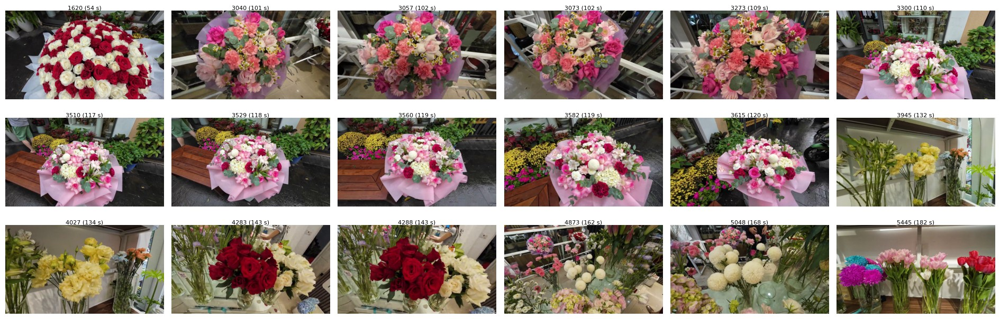

In [2]:
try:
    with FramePicker(path) as picker:
        picker.load()
        picks = list(picker.picks)
        frames = {f.index: f for f in picker.frames()}
except FileNotFoundError:
    raise SystemExit("No saved picks: run notebook 04 and press 'Save picks' first.")

print(f"{len(picks)} frames: {picks}")


def label(index):
    return f"{index} ({frames[index].time_s:.0f} s)"


def small(image):
    return image.resize((-(-image.width // SCALE), -(-image.height // SCALE)))


fig, axes = plt.subplots(3, 6, figsize=(19, 6.4))
for ax, index in zip(axes.ravel(), picks):
    ax.imshow(frames[index].image.resize((427, 240)))
    ax.set_title(label(index), fontsize=8, pad=2)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2 · Run SAM 3

One encode per frame, then the 11 prompts. The results of each frame are saved
as soon as it is done. Masks are kept at 1/3 resolution to save memory.

In [3]:
CACHE_DIR = DATASET_DIR / "cache" / "sam3_picks"
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def cache_file(index):
    return CACHE_DIR / f"{path.stem}_f{index}.npz"


res, todo = {}, {}
for index in picks:
    res[index] = sg.load_results(cache_file(index)) if cache_file(index).exists() else {}
    missing = [p for p in PROMPTS if p not in res[index]]
    if missing:
        todo[index] = missing
print(f"{len(picks)} frames x {len(PROMPTS)} prompts; frames that still need SAM 3: {len(todo)}")

frame_seconds = {}
if todo:
    sam3 = sg.Sam3TextSegmenter()
    started = time.perf_counter()
    for n, (index, missing) in enumerate(todo.items(), 1):
        t0 = time.perf_counter()
        new = sam3.segment_many(frames[index].image, missing, threshold=SAM3_LOW, downscale=SCALE)
        res[index] = {**res[index], **new}
        sg.save_results(cache_file(index), res[index])     # saved per frame: safe to interrupt
        frame_seconds[index] = time.perf_counter() - t0
        print(f"  {n}/{len(todo)} frame {label(index)}: {len(missing)} prompts in "
              f"{frame_seconds[index]:.0f} s (total {time.perf_counter() - started:.0f} s)", flush=True)
    del sam3
    gc.collect()

if frame_seconds:
    print(f"computed {len(frame_seconds)} frame(s): {np.mean(list(frame_seconds.values())):.0f} s per frame "
          f"for {len(PROMPTS)} prompts")


def keep(index, prompt, thr=SAM3_THR):
    return [i for i in res[index][prompt] if i.score >= thr]

18 frames x 11 prompts; frames that still need SAM 3: 0


## 3 · Which prompt fires where

Left: **number of masks** with score >= 0.5. Right: the **best score** of any
mask for that prompt. Read across a row to see where a word finds things;
a species that fires on frames where it is not present is a false alarm.

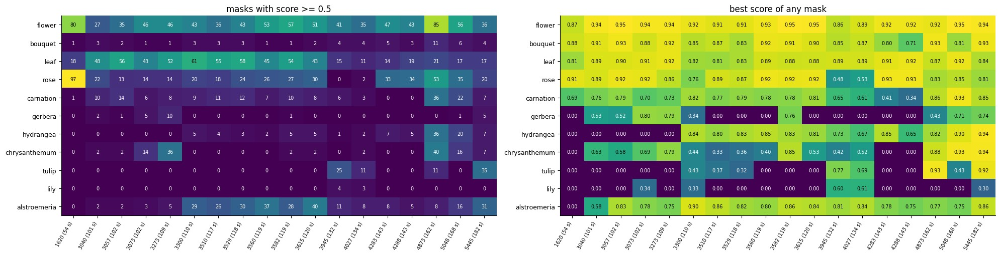

In [4]:
counts = pd.DataFrame({label(i): {p: len(keep(i, p)) for p in PROMPTS} for i in picks})
best = pd.DataFrame({label(i): {p: max((m.score for m in res[i][p]), default=0.0) for p in PROMPTS}
                     for i in picks})

fig, axes = plt.subplots(1, 2, figsize=(20, 5.2))
for ax, table, title, fmt in ((axes[0], counts, "masks with score >= 0.5", "{:.0f}"),
                              (axes[1], best, "best score of any mask", "{:.2f}")):
    ax.imshow(table.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index, fontsize=9)
    ax.set_title(title)
    top = table.values.max()
    for r in range(table.shape[0]):
        for c in range(table.shape[1]):
            value = table.values[r, c]
            ax.text(c, r, fmt.format(value), ha="center", va="center", fontsize=7,
                    color="white" if value < 0.6 * top else "black")
plt.tight_layout()
plt.show()

In [5]:
summary = pd.DataFrame({
    "frames with >= 1 mask": (counts > 0).sum(axis=1),
    "mean masks / frame": counts.mean(axis=1).round(1),
    "max masks in a frame": counts.max(axis=1),
    "total masks": counts.sum(axis=1),
})
summary.loc[PROMPTS]

,frames with >= 1 mask,mean masks / frame,max masks in a frame,total masks
flower,18,47.8,85,860
bouquet,18,3.2,11,58
leaf,18,35.9,61,647
rose,17,26.8,97,482
carnation,16,9.4,36,170
gerbera,7,1.4,10,25
hydrangea,13,5.7,36,102
chrysanthemum,10,6.8,40,123
tulip,4,4.6,35,82
lily,2,0.4,4,7


## 4 · Every frame, every prompt

One figure per prompt with all 18 frames (masks with score >= 0.5). Look for
masks on the *right* objects, and for masks where the species is not there.

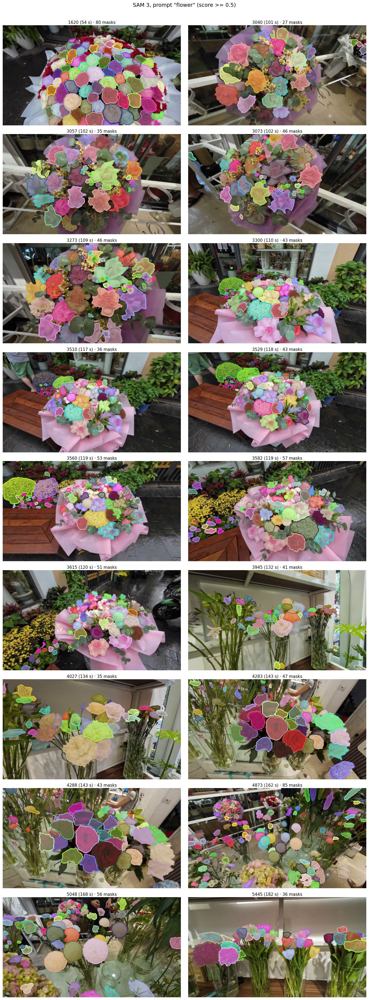

In [6]:
def show_prompt(prompt):
    # all frames, two per row, so each one is large enough to judge
    rows = -(-len(picks) // 2)
    fig, axes = plt.subplots(rows, 2, figsize=(14, 4.1 * rows))
    for ax, index in zip(axes.ravel(), picks):
        found = keep(index, prompt)
        ax.imshow(sg.overlay_instances(small(frames[index].image), found))
        ax.set_title(f"{label(index)} · {len(found)} masks", fontsize=11, pad=4)
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.6 / (4.1 * rows)))
    fig.suptitle(f'SAM 3, prompt "{prompt}" (score >= {SAM3_THR})', fontsize=14, y=1 - 0.1 / (4.1 * rows))
    plt.show()


show_prompt("flower")

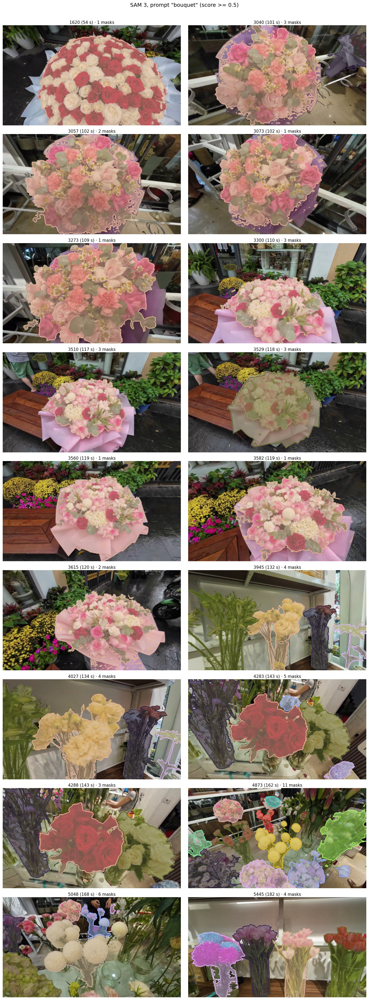

In [7]:
show_prompt("bouquet")

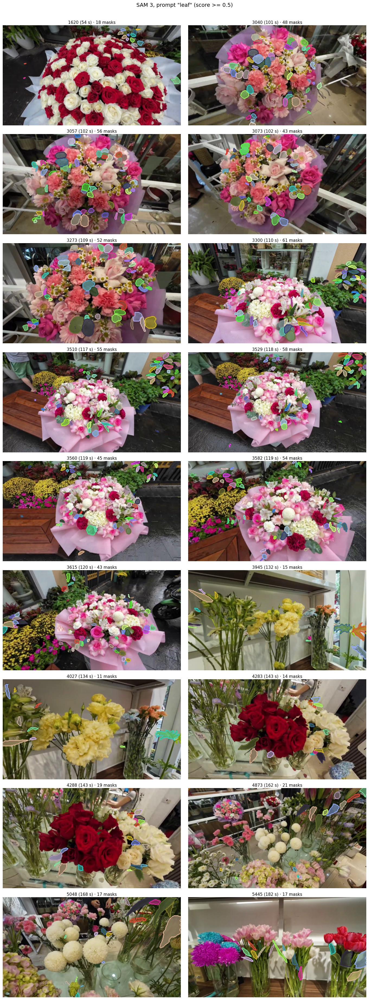

In [8]:
show_prompt("leaf")

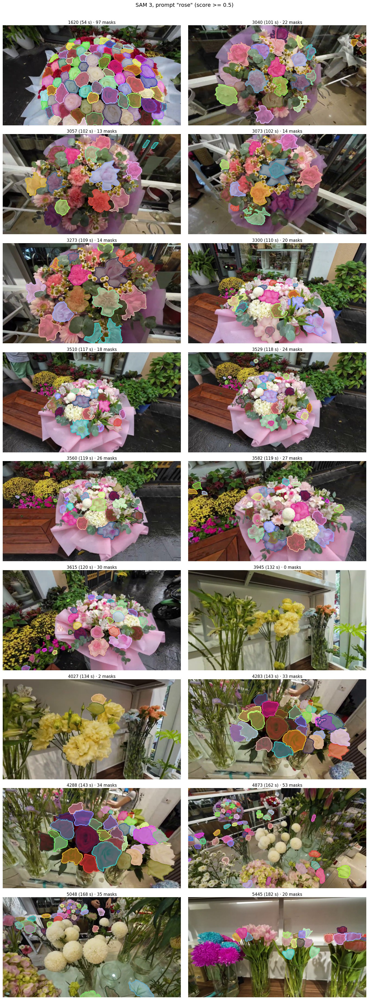

In [9]:
show_prompt("rose")

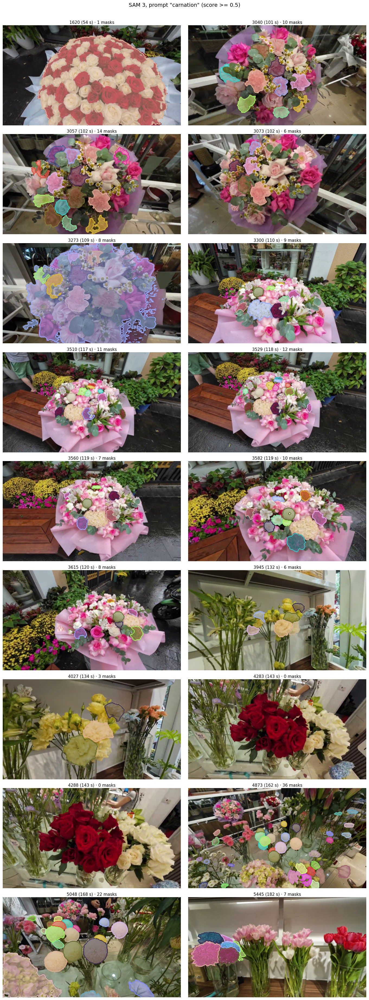

In [10]:
show_prompt("carnation")

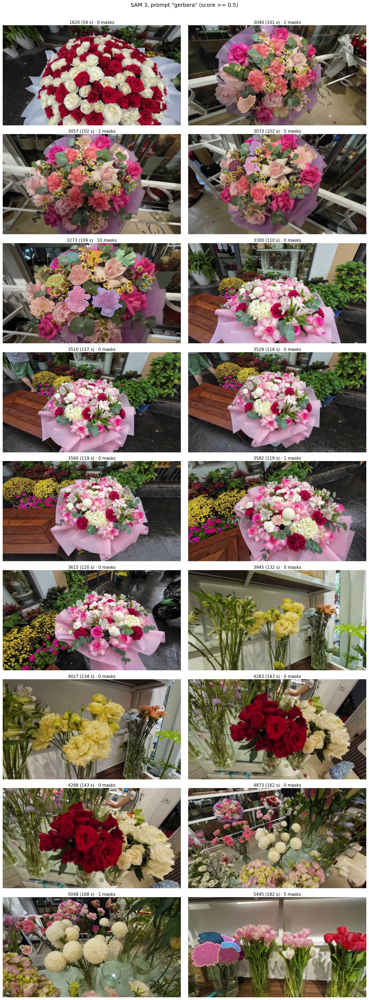

In [11]:
show_prompt("gerbera")

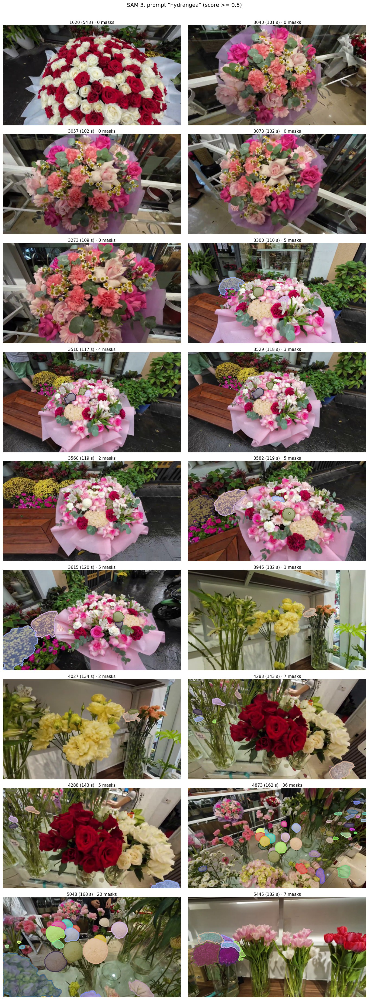

In [12]:
show_prompt("hydrangea")

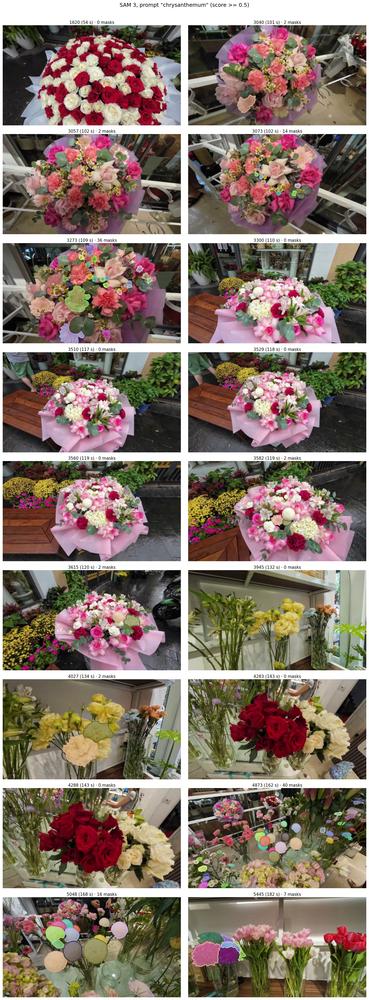

In [13]:
show_prompt("chrysanthemum")

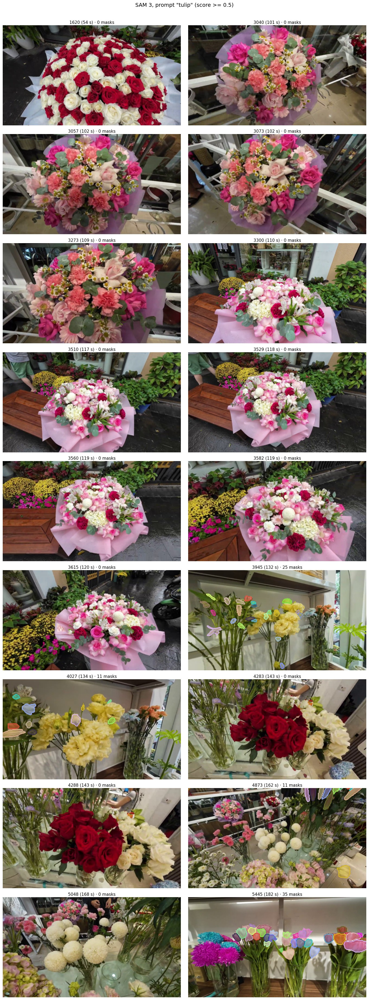

In [14]:
show_prompt("tulip")

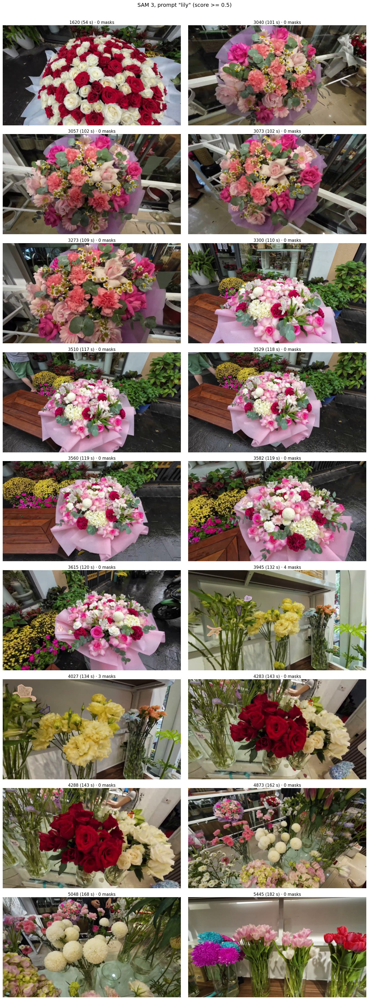

In [15]:
show_prompt("lily")

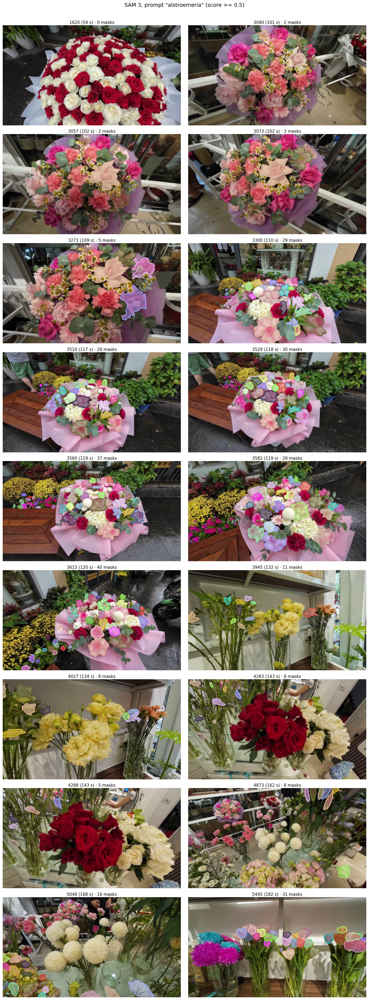

In [16]:
show_prompt("alstroemeria")

## 5 · Do the species prompts agree with each other?

If two different words claim the **same object** (mask IoU >= 0.5 on the same
frame), SAM 3 cannot tell those species apart. Entry (A, B) is the **share of
A's masks that have a matching B mask**, counted over all frames. A high value
off the diagonal means "A and B are mostly the same masks" (confusion); "flower"
is the reference for "is it a flower at all".

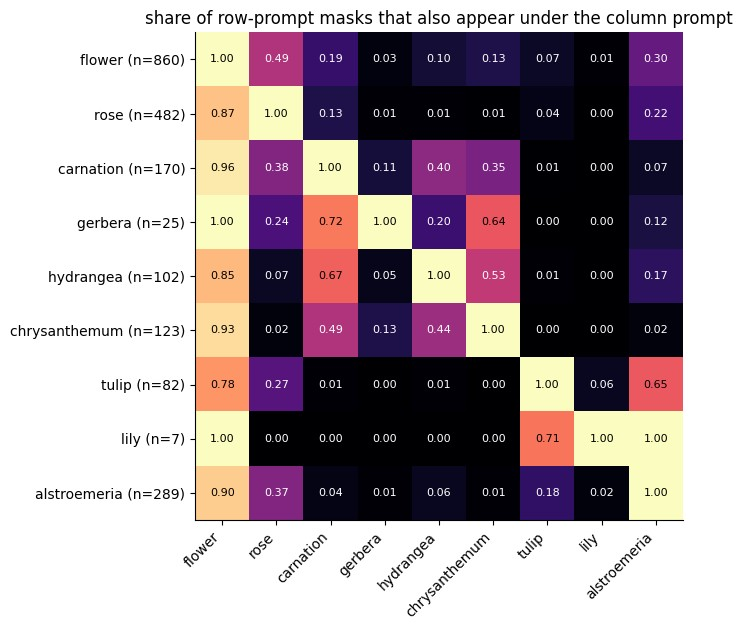

In [17]:
SPECIES = ["flower", "rose", "carnation", "gerbera", "hydrangea", "chrysanthemum", "tulip", "lily", "alstroemeria"]


def flat(masks):
    return np.stack([m.mask[::2, ::2].ravel() for m in masks]).astype(np.float32)


hit = pd.DataFrame(0.0, index=SPECIES, columns=SPECIES)
total = pd.Series(0, index=SPECIES)
for index in picks:
    stacks = {p: flat(keep(index, p)) for p in SPECIES if keep(index, p)}
    for p in SPECIES:
        total[p] += len(keep(index, p))
    for a in stacks:
        for b in stacks:
            inter = stacks[a] @ stacks[b].T
            union = stacks[a].sum(1)[:, None] + stacks[b].sum(1)[None, :] - inter
            iou = inter / np.maximum(union, 1)
            hit.loc[a, b] += int((iou.max(axis=1) >= 0.5).sum())
share = hit.div(total.replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(8.6, 6.4))
ax.imshow(share.values, cmap="magma", vmin=0, vmax=1)
ax.set_xticks(range(len(SPECIES)))
ax.set_xticklabels(SPECIES, rotation=45, ha="right")
ax.set_yticks(range(len(SPECIES)))
ax.set_yticklabels([f"{p} (n={int(total[p])})" for p in SPECIES])
for r in range(len(SPECIES)):
    for c in range(len(SPECIES)):
        v = share.values[r, c]
        if not np.isnan(v):
            ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v < 0.6 else "black")
ax.set_title("share of row-prompt masks that also appear under the column prompt")
plt.tight_layout()
plt.show()

## 6 · The toxic species: where does SAM 3 think they are?

For each toxic species: the two frames where it found the most masks.

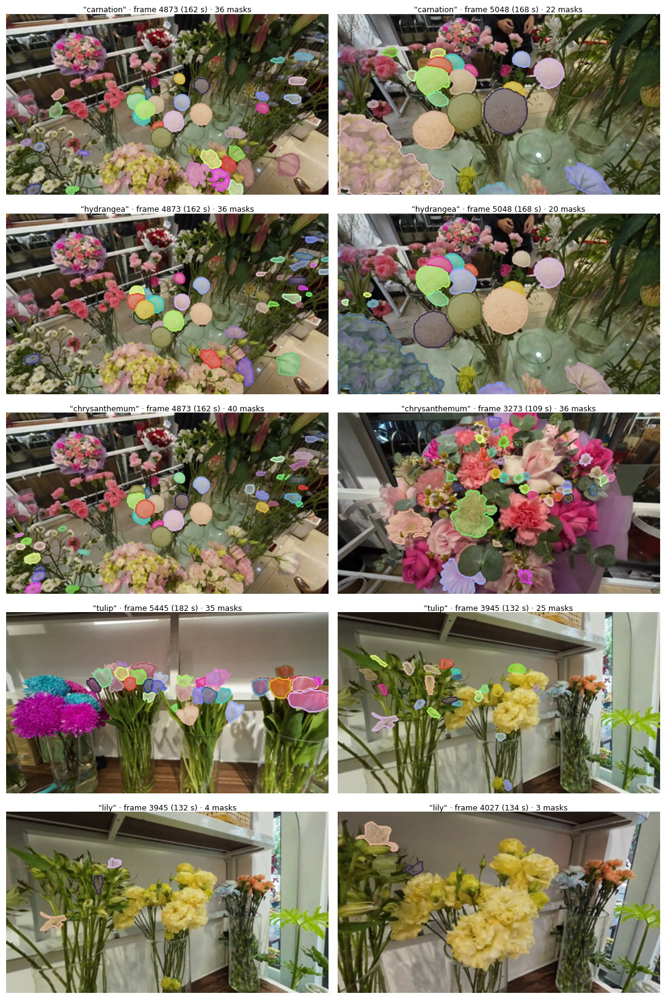

In [18]:
rows = []
for prompt in TOXIC:
    ranked = sorted(picks, key=lambda i: -len(keep(i, prompt)))[:2]
    rows.append((prompt, ranked))

fig, axes = plt.subplots(len(TOXIC), 2, figsize=(11, 3.3 * len(TOXIC)))
for r, (prompt, ranked) in enumerate(rows):
    for c, index in enumerate(ranked):
        found = keep(index, prompt)
        axes[r][c].imshow(sg.overlay_instances(small(frames[index].image), found).resize((640, 360)))
        axes[r][c].set_title(f'"{prompt}" · frame {label(index)} · {len(found)} masks', fontsize=9, pad=2)
        axes[r][c].axis("off")
plt.tight_layout()
plt.show()

## 7 · How much does the threshold matter?

Total masks over all 18 frames at each score threshold. SAM 3 gives a score
per mask, so this is the trade-off between finding more and being wrong more.

In [19]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
sens = pd.DataFrame({f">= {t}": {p: sum(len(keep(i, p, t)) for i in picks) for p in PROMPTS} for t in thresholds})
sens

,>= 0.3,>= 0.4,>= 0.5,>= 0.6,>= 0.7,>= 0.8
flower,1264,1042,860,666,465,265
bouquet,98,77,58,47,37,26
leaf,1055,818,647,493,301,125
rose,926,671,482,346,232,125
carnation,503,303,170,104,58,28
gerbera,106,46,25,14,10,0
hydrangea,305,168,102,69,45,26
chrysanthemum,316,210,123,67,43,29
tulip,183,120,82,55,33,19
lily,21,10,7,2,0,0


## 8 · Take-aways (SAM 3 prompts)

There is no ground truth for these 18 frames, so everything below is a
judgement from the pictures and the counts, not a measured accuracy. The
numbers come from the tables above.

**Generic prompts work; species prompts mostly do not.**

* **`flower` is the reliable one.** It fires in 18/18 frames with a best score
  of 0.86 or more and 36-85 masks per frame at score >= 0.5. This is the
  "where are the flower heads" answer.
* **`leaf` also fires everywhere** (mean 36 masks/frame). Useful as a
  *negative* class: a flower mask that is also a leaf mask is suspect.
* **`bouquet` gives 1-11 masks**: a usable "this is a bouquet" region, no more.
* **`rose` is the only species word that clearly means something.** It finds
  97 masks on the all-rose bouquet (frame 1620) and the red roses in frame
  4283, and stays at 0-2 on the shelf frames with no roses (3945, 4027). But in
  the pink mixed bouquets (frames 3040-3615) it also marks carnations and
  other flowers, so it is "rose-like", not "rose".
* **`carnation`, `hydrangea`, `chrysanthemum` mark largely the same blobs.**
  In the overlap matrix 40% of the carnation masks are also hydrangea masks,
  35% also chrysanthemum, and 67% of the hydrangea masks are also carnation
  masks. In the gallery the three prompts outline the same round pom-pom
  flowers and small blooms in frame 4873. Only `hydrangea` in frame 5048
  clearly picks out the real hydrangea (bottom left), and there `carnation`
  outlines it as well.
* **Scores are not species evidence.** A prompt that fires does so with a high
  score whether or not the flower is right (`rose` best scores 0.76-0.92
  wherever it fires; the columns showing 0.00 only mean nothing passed the 0.30
  floor). Do not read "score 0.9" as "90% sure it is a rose".

**The dangerous failure is a miss, not a false alarm.**

* `lily` finds 7 masks in total and none in the wide frame 4873, where the
  large pink flowers at the top of the frame look like lilies by eye. The
  masks it does produce (frames 3945/4027) sit on small flowers that do not
  look like lilies. If we trusted "no `lily` mask => no lily", we would
  wrongly call a bouquet safe.
* `tulip` fires in only 4 frames and `gerbera` in 7, so even the flowers we
  asked for by name are found in a minority of frames.
* The rule "unknown / not found => assume toxic" therefore must not be built
  on top of prompt hits. A prompt that does not fire says nothing.

**Thresholds matter a lot for the specific prompts.** Going from 0.3 to 0.5
drops `flower` masks by a third (1264 -> 860) but `carnation` by two thirds
(503 -> 170), `lily` from 21 to 7 and `gerbera` from 106 to 25. The species
prompts live in the low-score region, where they are least trustworthy.

**Cost.** 11 prompts on one frame took about 106 s in this run (about 74 s in
the earlier two-frame test: the laptop load varies). Encoding the image once
and re-using it for every prompt is what makes this bearable (3.2x faster than
separate calls); 18 frames still took about half an hour. This is a lab tool,
not something for a live stream.

**What this means for the pipeline.** SAM 3 is a good *flower finder* (the
`flower` prompt, optionally minus `leaf`) and a poor *flower namer*. The
naming has to come from a separate classifier applied to each mask's crop, with
the existing safety rules (low confidence or unknown species => treated as
toxic). This is the "SAM 3 at run time + classifier" route from the earlier
discussion. It is also the reason not to use SAM 3 species prompts as labels
for training a YOLO model: the labels would be wrong in exactly the mixed
bouquets we care about.

**Next experiments.**

1. Crop the `flower` masks (>= 0.5, leaf overlap removed) and classify them
   with the Oxford ViT / DINOv2 kNN; look at how often the top species is
   confident, and what it says for carnations, hydrangeas and lilies.
2. Hand-label a small sample (say 50 crops, one click each) to turn "looks
   right" into a real accuracy figure. This is much cheaper than drawing
   boxes.
3. Check how stable the masks are from one frame to the next, since a live
   verdict needs a stable answer.

## 9 · Cheaper alternatives: classical and small models

SAM 3 finds the flower heads well but needs about 50 s per frame on this CPU.
What could run **close to real time**? This part tries, on the same 18 frames:

* **Classical computer vision** (OpenCV, scipy, scikit-image; no training):
  HSV colour threshold, k-means, mean-shift, Felzenszwalb, SLIC superpixels,
  quick shift, watershed on the colour mask, MSER, Hough circles, DoG blob
  detector, Canny edge regions, and GrabCut as a per-flower refinement.
* **Small deep models** (segment-everything, no text): FastSAM-s (23 MB),
  MobileSAM (39 MB, one prompt point per grid cell) and SAM 2.1 tiny.

Every method is run with **several parameter settings**.

**A fair comparison needs one shared rule.** None of these methods knows what
a flower is, they only return *segments* (leaves, wrapping paper, vases
included). So each method's output goes through the same, deliberately simple
filter `classical.flowerlike`: not mostly green, not grey, a plausible size
(0.04 - 5 % of the image) and compact (solidity >= 0.7). What is left are
**flower-head candidates**. White flowers are lost by the "not grey" rule and
that is a known weakness, the same for every method.

**How results are compared with SAM 3.** SAM 3's `flower` masks (score >= 0.5)
are the **reference**, but they are *not ground truth*: SAM 3 also
mislabels some leaves and misses flowers. So the numbers below mean
"agrees with SAM 3", not "is correct". For each method and frame:

* **recall**: share of SAM 3's flower masks that have a candidate with mask
  IoU >= 0.5 (one-to-one),
* **precision**: share of candidates that have such a SAM 3 mask,
* **F1**: their harmonic mean (instance level),
* **pixel F1**: how well the *union* of all candidate pixels overlaps the union
  of SAM 3's pixels (region level, forgiving of merged or split flowers).

The classical methods run on the same 427 x 240 image that SAM 3's stored masks
use. The deep models (FastSAM, MobileSAM, SAM 2.1) are given the **full
1280 x 720 frame** and their masks are shrunk to 427 x 240 afterwards, so their
timings are for the full-size frame. Filtered candidates and timings are cached in
`data/raw/cache/small_seg/`; if you change a setting, change its label too.

In [20]:
import json
import re

from bouquet_checker import classical as cl

SMALL_DIR = DATASET_DIR / "cache" / "small_seg"
SMALL_DIR.mkdir(parents=True, exist_ok=True)

small_frames = {index: small(frames[index].image) for index in picks}
MODELS = {}                                 # loaded lazily, freed after use


def model(name):
    if name not in MODELS:
        MODELS[name] = {"fastsam": sg.FastSamSegmenter,
                        "mobilesam": sg.MobileSamSegmenter,
                        "sam2": sg.Sam2AutoMasker}[name]()
    return MODELS[name]


def shrink(instances):
    # SAM 2 returns full-size masks: keep every SCALE-th pixel like SAM 3's
    return [sg.Instance(i.mask[::SCALE, ::SCALE], i.score, i.label) for i in instances]


def on_small(function, **kwargs):
    # a classical method: takes the small image
    return lambda full, tiny: function(tiny, **kwargs)


def grabcut_on_colour(sat, iterations):
    def run(full, tiny):
        seeds = cl.colour_blobs(tiny, sat_min=sat)
        return cl.grabcut_refine(tiny, seeds, iterations=iterations)
    return run


# family -> [(setting label, function(full-size image, small image))]
SWEEPS = {
    "HSV colour threshold": (
        [(f"saturation >= {s}", on_small(cl.colour_blobs, sat_min=s)) for s in (60, 100, 140)]
        + [("saturation >= 100, plus white", on_small(cl.colour_blobs, sat_min=100, include_white=True))]),
    "k-means (Lab)": [(f"k = {k}", on_small(cl.kmeans_segments, k=k)) for k in (4, 8, 12)],
    "mean-shift": [(f"spatial {sp} / colour {sr}", on_small(cl.meanshift_segments, sp=sp, sr=sr))
                   for sp, sr in ((6, 12), (8, 16), (12, 24))],
    "Felzenszwalb": [(f"scale {s}", on_small(cl.felzenszwalb_segments, scale=s)) for s in (50, 100, 200, 400)],
    "SLIC superpixels": (
        [(f"{n} superpixels", on_small(cl.slic_segments, n_segments=n)) for n in (100, 200, 400)]
        + [("400 superpixels, merged (colour 20)", on_small(cl.slic_segments, n_segments=400, merge=20.0))]),
    "quick shift": [(f"kernel {k} / max dist {d}", on_small(cl.quickshift_segments, kernel_size=k, max_dist=d))
                    for k, d in ((3, 6), (5, 10), (3, 12))],
    "watershed (colour mask)": [(f"min distance {d}px", on_small(cl.watershed_segments, min_distance=d))
                                for d in (3, 6, 10)],
    "MSER": [(f"delta {d}", on_small(cl.mser_segments, delta=d)) for d in (3, 5, 8)],
    "Hough circles": [(f"accumulator {p}", on_small(cl.hough_circles, param2=p)) for p in (15, 25, 35)],
    "DoG blobs": [
        ("saturation, sigma 2-10", on_small(cl.dog_blobs)),
        ("saturation, sigma 3-14", on_small(cl.dog_blobs, min_sigma=3, max_sigma=14)),
        ("saturation, sigma 2-10, threshold 0.1", on_small(cl.dog_blobs, threshold=0.1)),
        ("grey, sigma 2-10", on_small(cl.dog_blobs, channel="grey"))],
    "Canny edge regions": [(f"thresholds {lo}/{hi}", on_small(cl.edge_contours, low=lo, high=hi))
                           for lo, hi in ((20, 60), (40, 120), (80, 200))],
    "GrabCut on colour blobs": [(f"{n} iteration(s)", grabcut_on_colour(100, n)) for n in (1, 3)],
    "FastSAM-s": [
        ("imgsz 640, conf 0.4", lambda full, tiny: model("fastsam").segment(full, imgsz=640, conf=0.4)),
        ("imgsz 1024, conf 0.4", lambda full, tiny: model("fastsam").segment(full, imgsz=1024, conf=0.4)),
        ("imgsz 1024, conf 0.2", lambda full, tiny: model("fastsam").segment(full, imgsz=1024, conf=0.2)),
        ("imgsz 1024, conf 0.6, iou 0.7",
         lambda full, tiny: model("fastsam").segment(full, imgsz=1024, conf=0.6, iou=0.7))],
    "MobileSAM (point grid)": [
        (f"{g} x {g} points", lambda full, tiny, g=g: cl.dedupe(model("mobilesam").segment(full, grid=g), 0.8))
        for g in (6, 8)],
    "SAM 2.1 tiny (auto)": [
        (f"{g} x {g} points", lambda full, tiny, g=g: shrink(model("sam2").segment(full, points_per_crop=g)))
        for g in (8, 12)],
}
DEEP = ["FastSAM-s", "MobileSAM (point grid)", "SAM 2.1 tiny (auto)"]
print(f"{sum(len(v) for v in SWEEPS.values())} settings in {len(SWEEPS)} methods, "
      f"{len(picks)} frames each")

47 settings in 15 methods, 18 frames each


## 10 · Run everything

For each setting and frame: segment, filter with `flowerlike`, compare with
SAM 3, save. Only the segmentation itself is timed. The small deep models take
the longest (SAM 2.1 tiny about 20-50 s per frame, MobileSAM 10-20 s), the
classical methods a fraction of a second each. Cached, so re-runs are quick.

In [21]:
def slug(text):
    return re.sub(r"[^a-z0-9]+", "-", text.lower()).strip("-")


def cache_stem(family, setting, index):
    return SMALL_DIR / f"{path.stem}_{slug(family)}__{slug(setting)}_f{index}"


def candidates(family, setting, index):
    return sg.load_results(cache_stem(family, setting, index).with_suffix(".npz"))["kept"]


def run_setting(family, setting, function):
    rows = []
    for index in picks:
        stem = cache_stem(family, setting, index)
        npz, meta_file = stem.with_suffix(".npz"), stem.with_suffix(".json")
        if npz.exists() and meta_file.exists():
            kept = sg.load_results(npz)["kept"]
            meta = json.loads(meta_file.read_text())
        else:
            tiny = small_frames[index]
            started = time.perf_counter()
            raw = function(frames[index].image, tiny)
            seconds = time.perf_counter() - started
            kept = cl.flowerlike(raw, tiny)
            sg.save_results(npz, {"kept": kept})
            meta = {"raw": len(raw), "seconds": seconds}
            meta_file.write_text(json.dumps(meta))
        agree = cl.agreement(keep(index, "flower"), kept)
        rows.append({"method": family, "setting": setting, "frame": index,
                     "raw": meta["raw"], "kept": len(kept), "seconds": meta["seconds"], **agree})
    return rows


all_rows = []
started = time.perf_counter()
for family, settings in SWEEPS.items():
    for setting, function in settings:
        rows = run_setting(family, setting, function)
        all_rows.extend(rows)
        frame = pd.DataFrame(rows)
        print(f"{family:<26} {setting:<38} {frame.seconds.mean():6.2f} s/frame  "
              f"{frame.kept.mean():6.1f} candidates/frame  recall {frame.recall.mean():.2f}  "
              f"precision {frame.precision.mean():.2f}", flush=True)
    if family in DEEP:
        MODELS.clear()
        gc.collect()
scores = pd.DataFrame(all_rows)
print(f"done in {time.perf_counter() - started:.0f} s (cached settings cost nothing)")

HSV colour threshold       saturation >= 60                         0.00 s/frame    22.3 candidates/frame  recall 0.05  precision 0.11


HSV colour threshold       saturation >= 100                        0.00 s/frame    23.7 candidates/frame  recall 0.10  precision 0.20


HSV colour threshold       saturation >= 140                        0.00 s/frame    19.5 candidates/frame  recall 0.11  precision 0.23


HSV colour threshold       saturation >= 100, plus white            0.00 s/frame    22.1 candidates/frame  recall 0.08  precision 0.19


k-means (Lab)              k = 4                                    0.04 s/frame    42.4 candidates/frame  recall 0.05  precision 0.07


...

MobileSAM (point grid)     6 x 6 points                             4.71 s/frame    10.6 candidates/frame  recall 0.08  precision 0.35


MobileSAM (point grid)     8 x 8 points                             6.83 s/frame    16.8 candidates/frame  recall 0.13  precision 0.35


SAM 2.1 tiny (auto)        8 x 8 points                             9.22 s/frame     7.3 candidates/frame  recall 0.09  precision 0.56


SAM 2.1 tiny (auto)        12 x 12 points                          21.59 s/frame    13.2 candidates/frame  recall 0.15  precision 0.53


done in 109 s (cached settings cost nothing)


## 11 · What the raw output looks like

One frame (3057, a close bouquet), each classical method with a middle
setting, **before** the `flowerlike` filter. Colours are random per segment.
The number is how many segments the method returned. This is why the filter
is needed, and why "number of segments" alone means nothing.

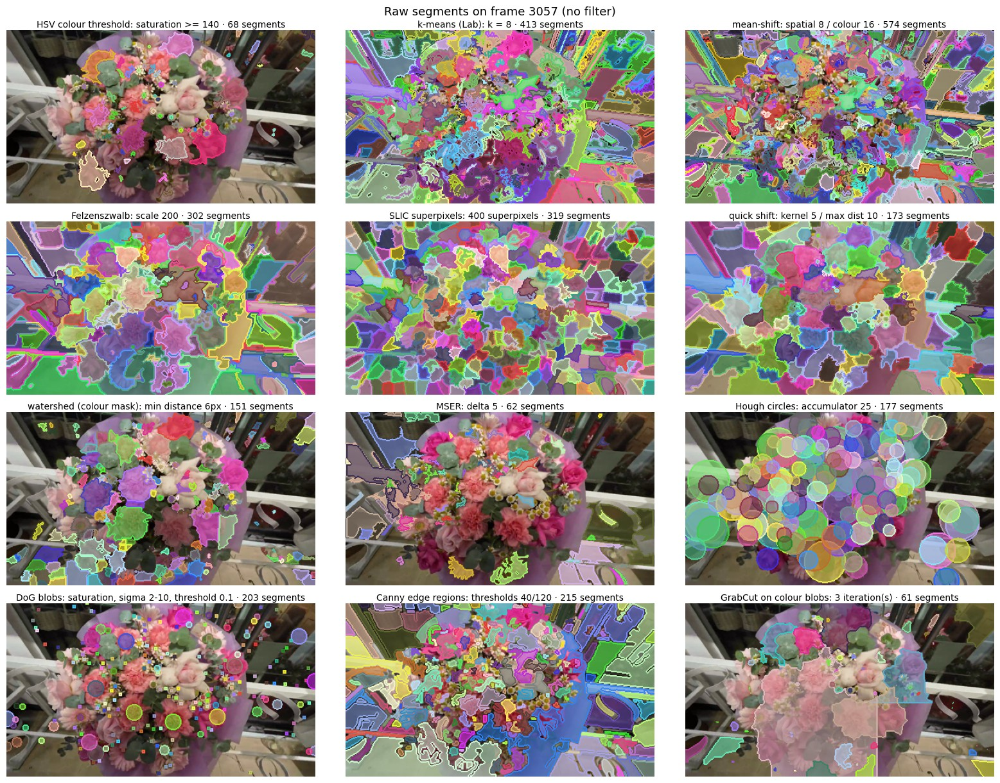

In [22]:
DEMO = 3057
demo_image = small_frames[DEMO]
raw_examples = {name: SWEEPS[name][len(SWEEPS[name]) // 2] for name in SWEEPS if name not in DEEP}

names = list(raw_examples)
cols = 3
rows_n = -(-len(names) // cols)
fig, axes = plt.subplots(rows_n, cols, figsize=(16, 3.1 * rows_n))
for ax, name in zip(axes.ravel(), names):
    setting, function = raw_examples[name]
    raw = function(frames[DEMO].image, demo_image)
    ax.imshow(sg.overlay_instances(demo_image, raw, alpha=0.55))
    ax.set_title(f"{name}: {setting} · {len(raw)} segments", fontsize=10, pad=3)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(f"Raw segments on frame {DEMO} (no filter)", fontsize=13)
plt.tight_layout()
plt.show()

## 12 · Parameter sweeps

One figure per method. Row 1 is always **SAM 3 "flower"** (the reference).
Each further row is one setting of the method, *after* the flower filter,
with its number of candidates and its recall / precision against SAM 3 for
that frame. Columns: a close bouquet (3057), a wide shop shot (4873) and the
tulip vases (5445).

In [23]:
SHOW = [3057, 4873, 5445]


def sweep_figure(family):
    settings = SWEEPS[family]
    fig, axes = plt.subplots(len(settings) + 1, len(SHOW), figsize=(16, 3.0 * (len(settings) + 1)))
    for c, index in enumerate(SHOW):
        ref = keep(index, "flower")
        axes[0, c].imshow(sg.overlay_instances(small_frames[index], ref))
        axes[0, c].set_title(f"SAM 3 'flower' · {label(index)} · {len(ref)} masks", fontsize=10, pad=3)
        for r, (setting, _) in enumerate(settings, 1):
            found = candidates(family, setting, index)
            a = cl.agreement(ref, found)
            axes[r, c].imshow(sg.overlay_instances(small_frames[index], found))
            axes[r, c].set_title(f"{setting} · {len(found)} · recall {a['recall']:.2f} · "
                                 f"precision {a['precision']:.2f}", fontsize=10, pad=3)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle(family, fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.5 / (3.0 * (len(settings) + 1))))
    plt.show()

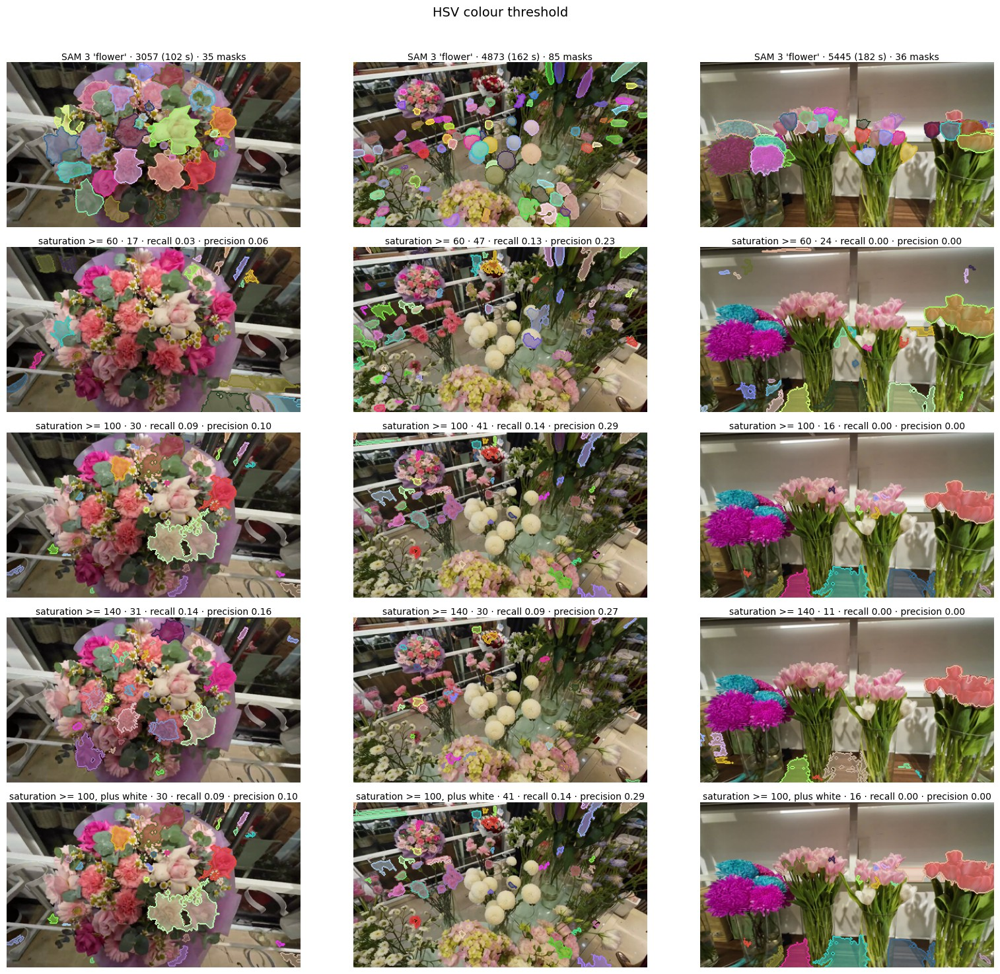

In [24]:
sweep_figure("HSV colour threshold")

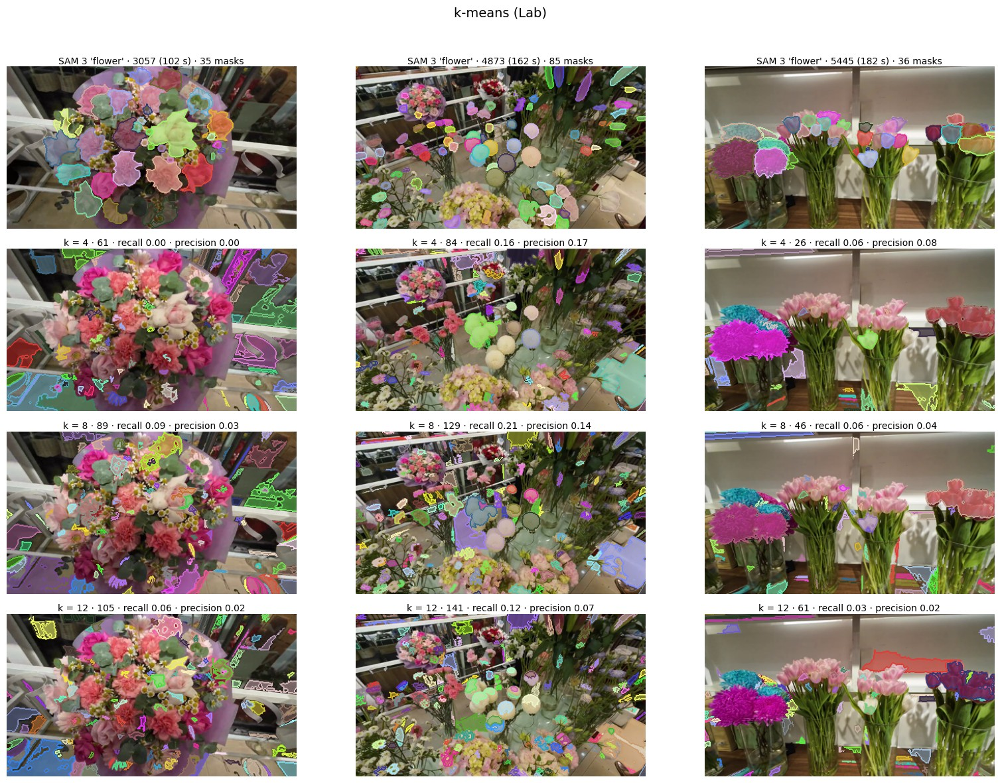

In [25]:
sweep_figure("k-means (Lab)")

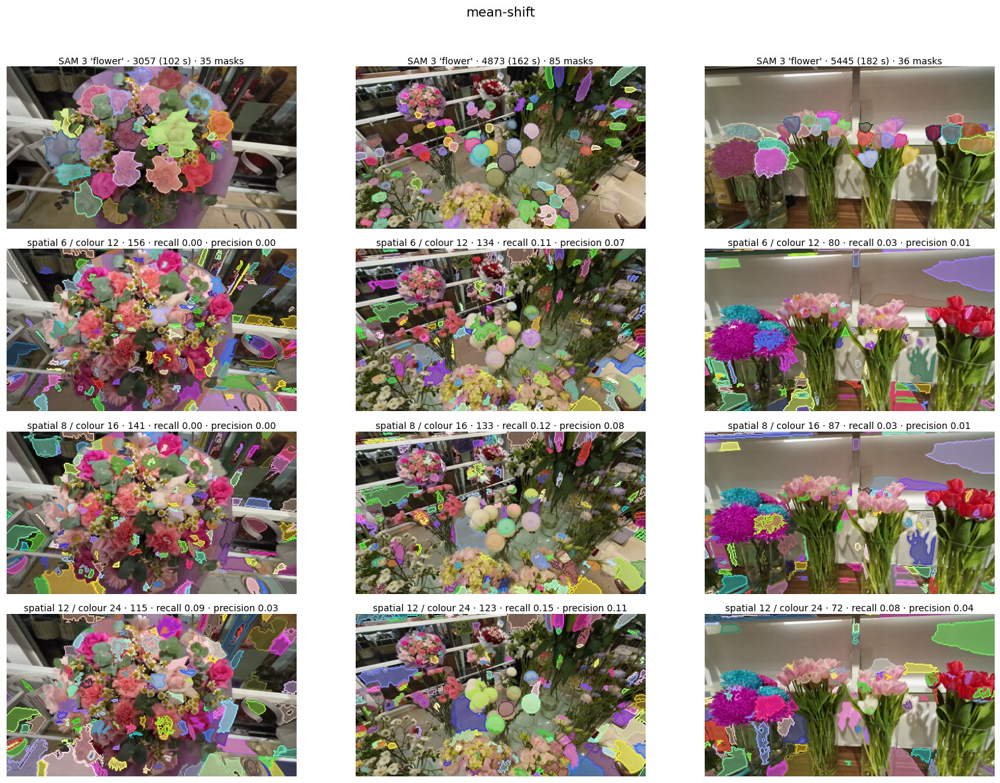

In [26]:
sweep_figure("mean-shift")

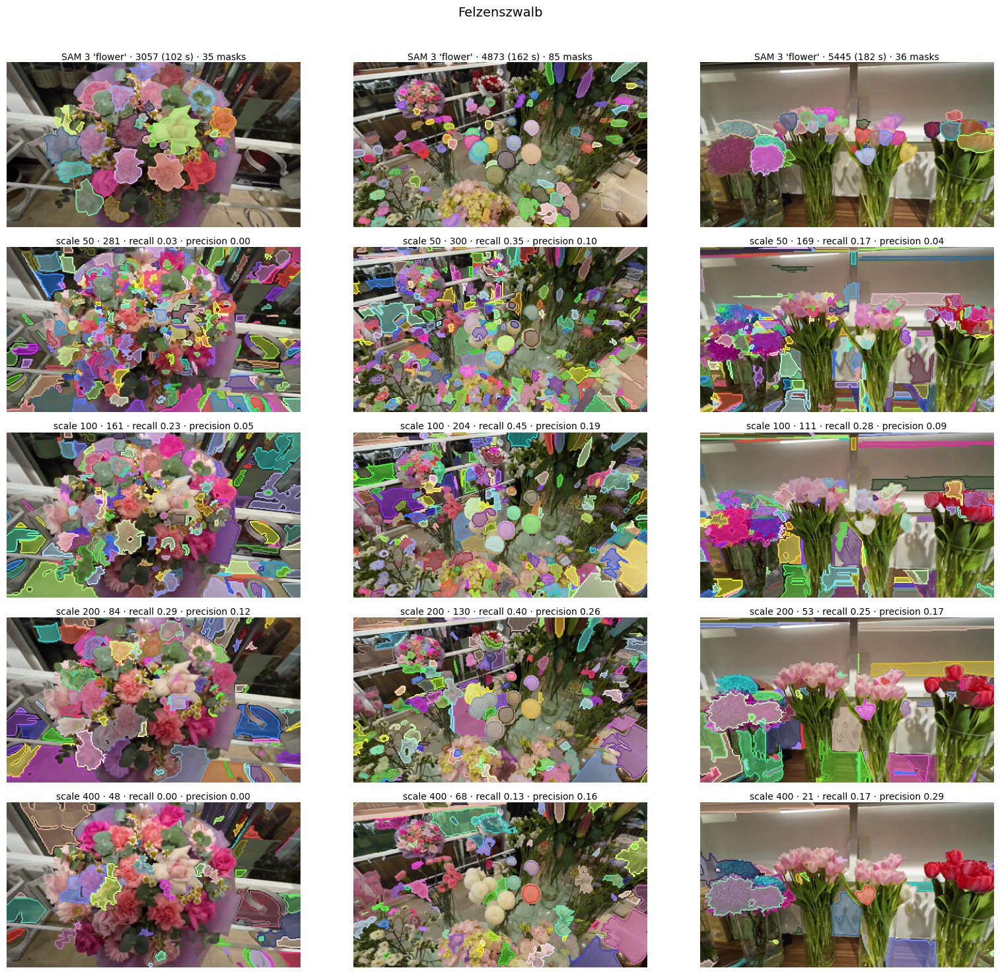

In [27]:
sweep_figure("Felzenszwalb")

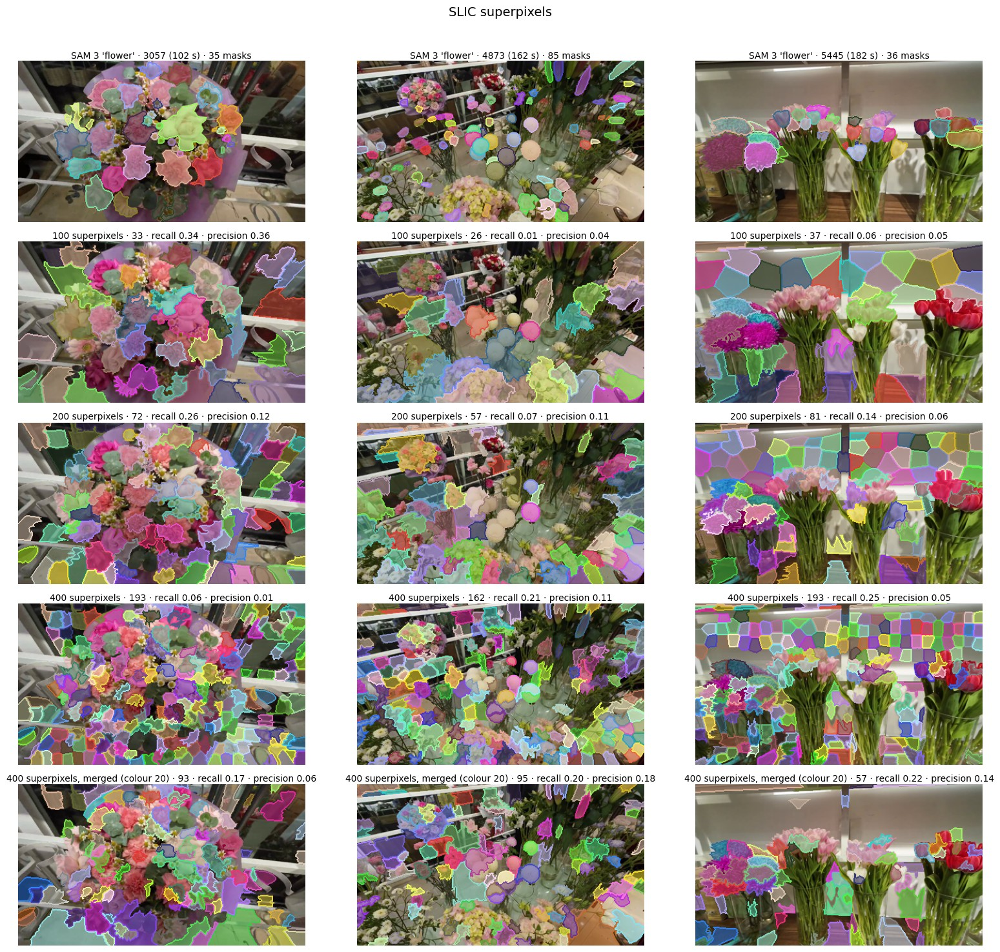

In [28]:
sweep_figure("SLIC superpixels")

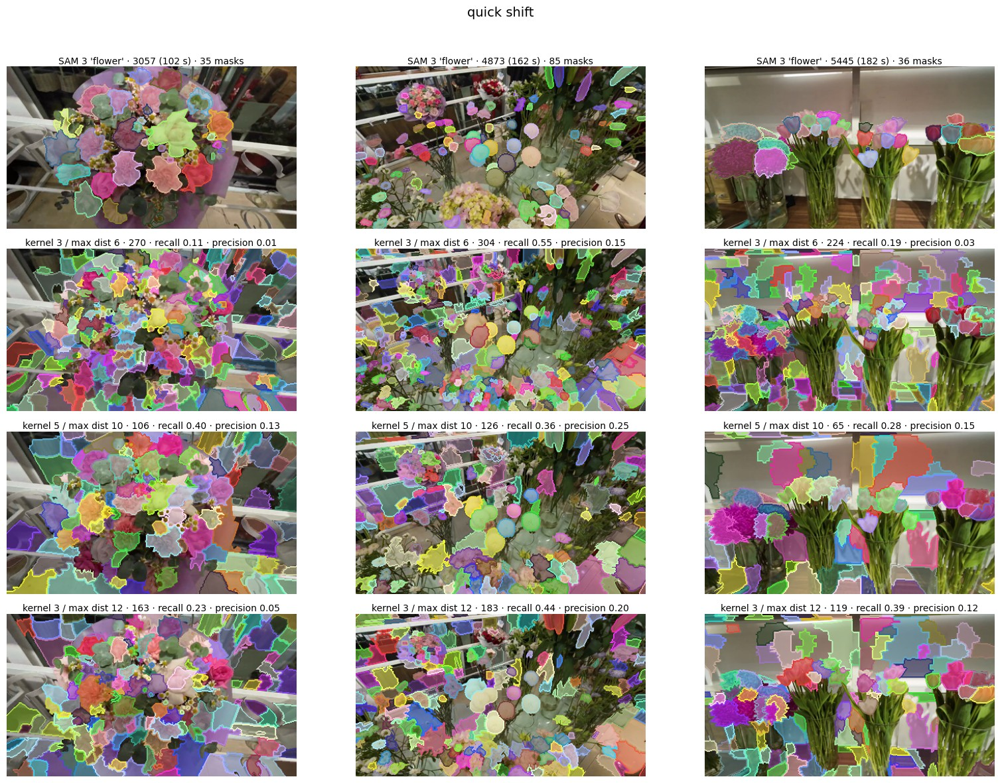

In [29]:
sweep_figure("quick shift")

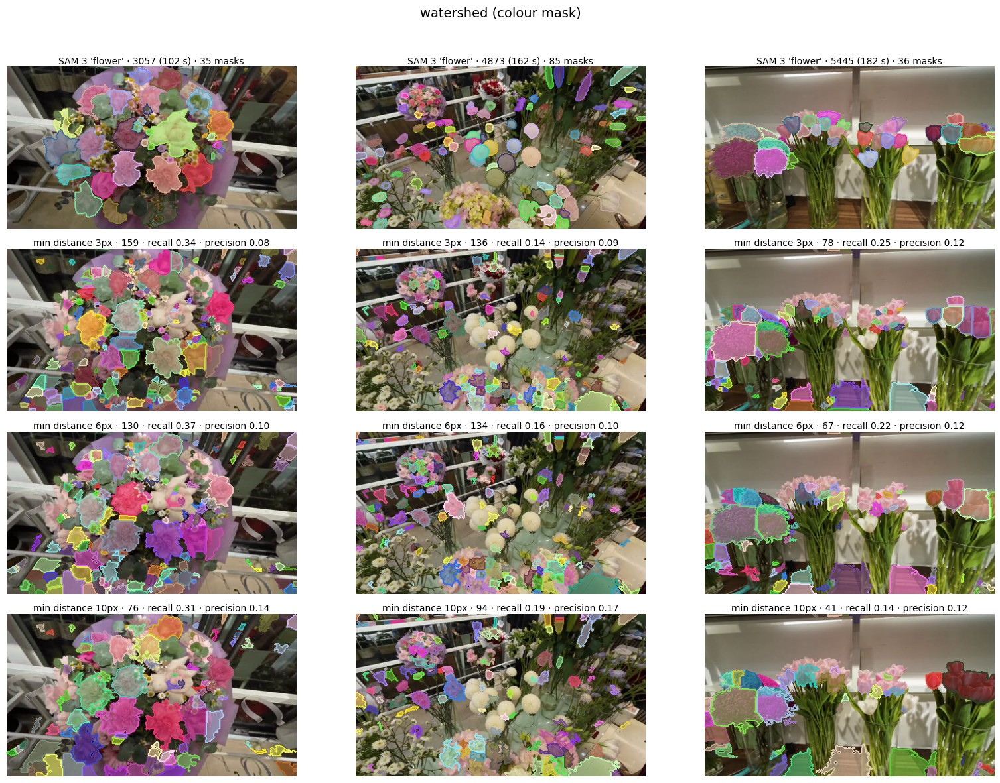

In [30]:
sweep_figure("watershed (colour mask)")

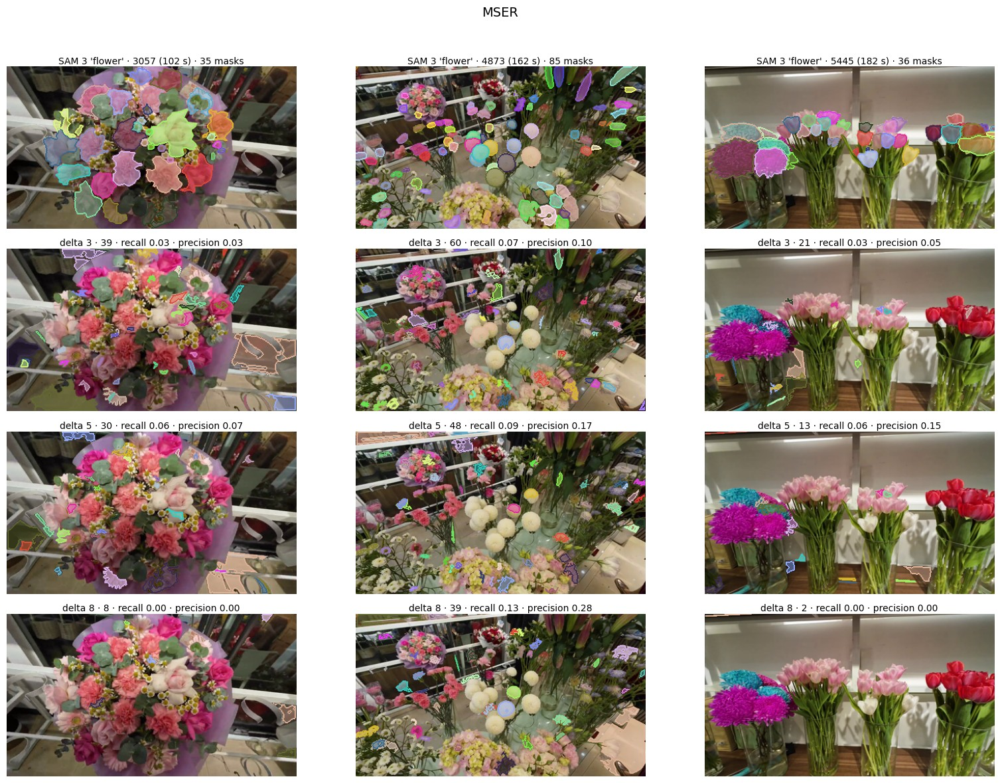

In [31]:
sweep_figure("MSER")

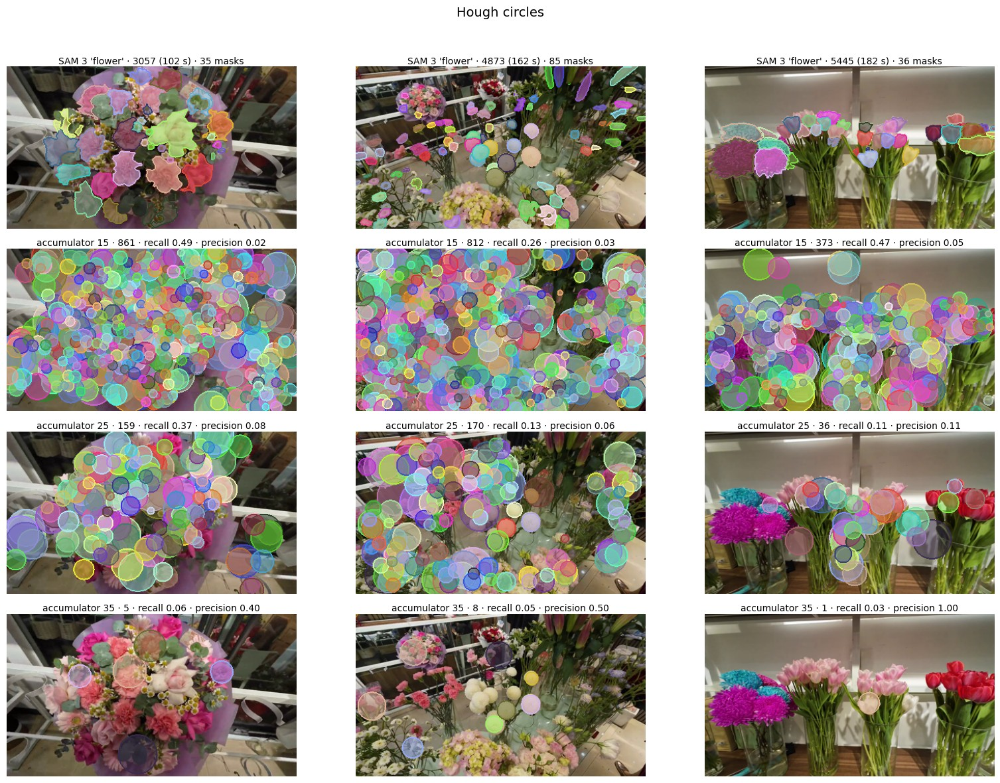

In [32]:
sweep_figure("Hough circles")

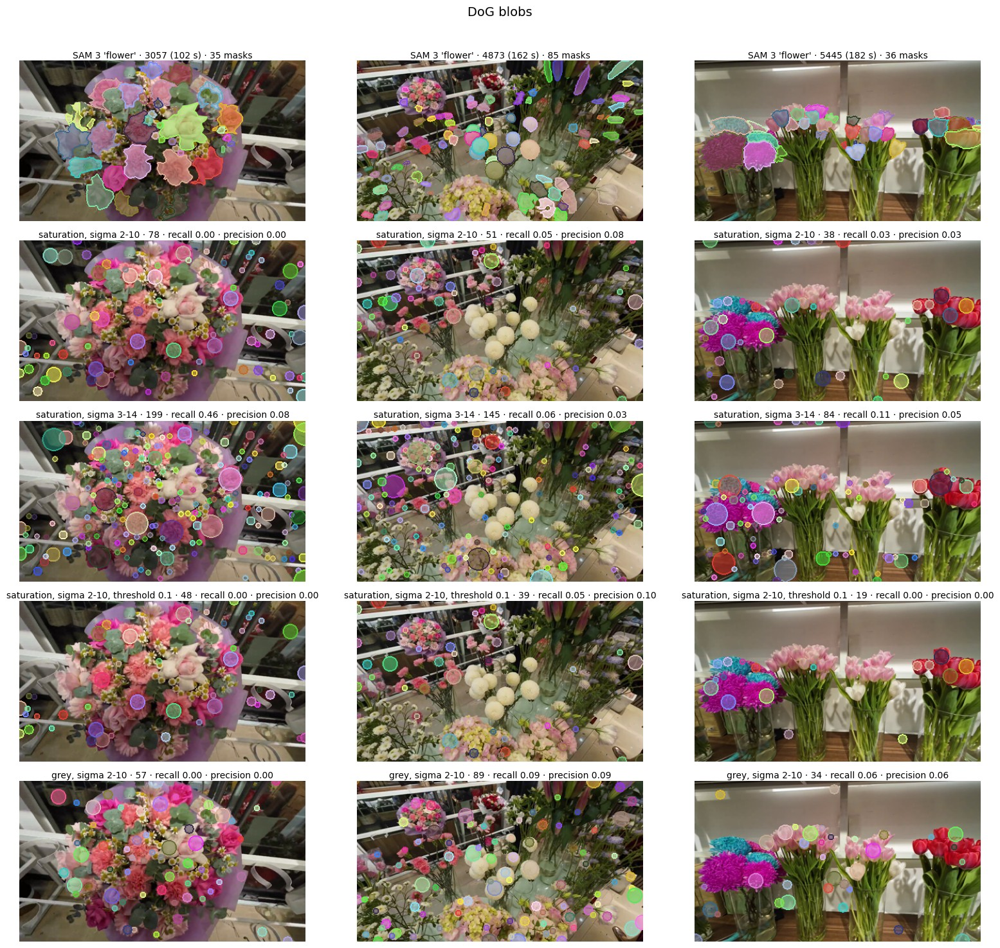

In [33]:
sweep_figure("DoG blobs")

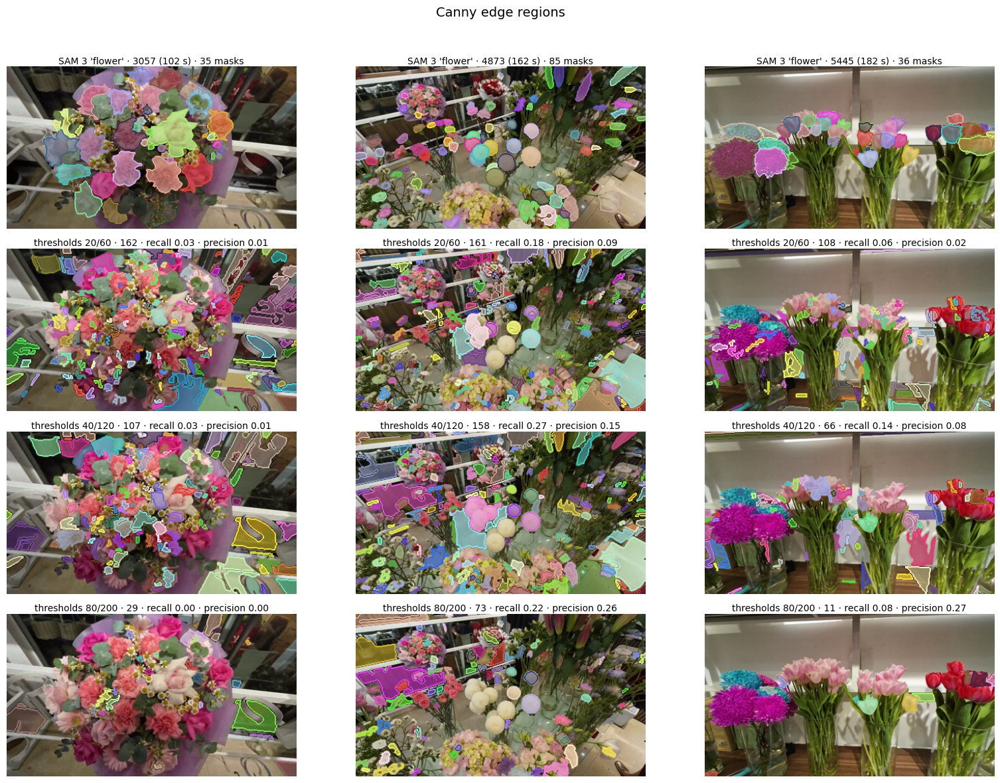

In [34]:
sweep_figure("Canny edge regions")

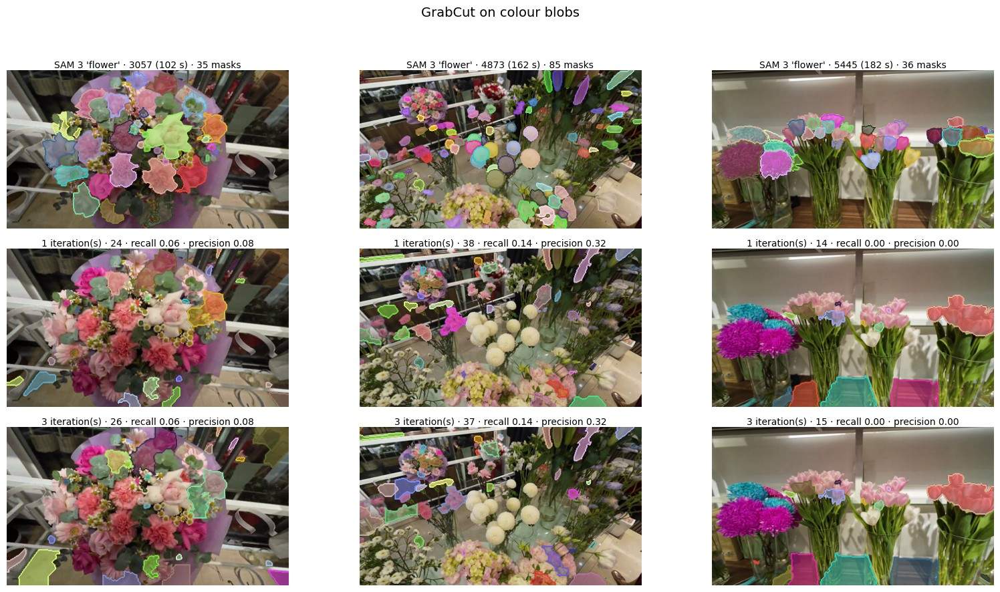

In [35]:
sweep_figure("GrabCut on colour blobs")

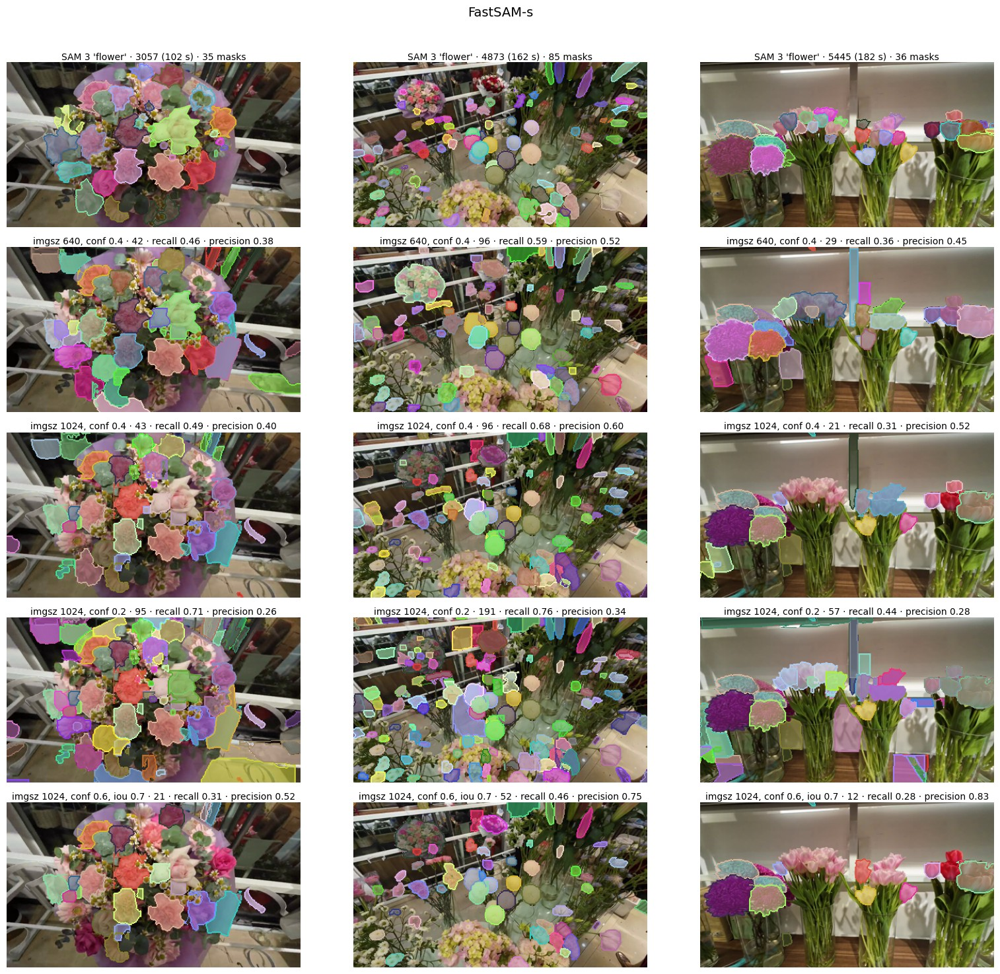

In [36]:
sweep_figure("FastSAM-s")

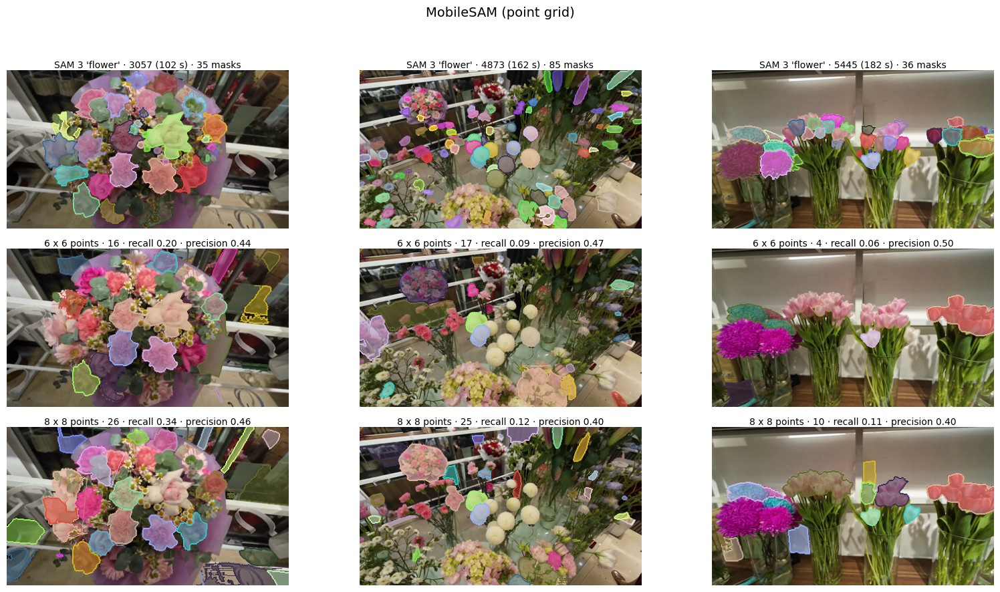

In [37]:
sweep_figure("MobileSAM (point grid)")

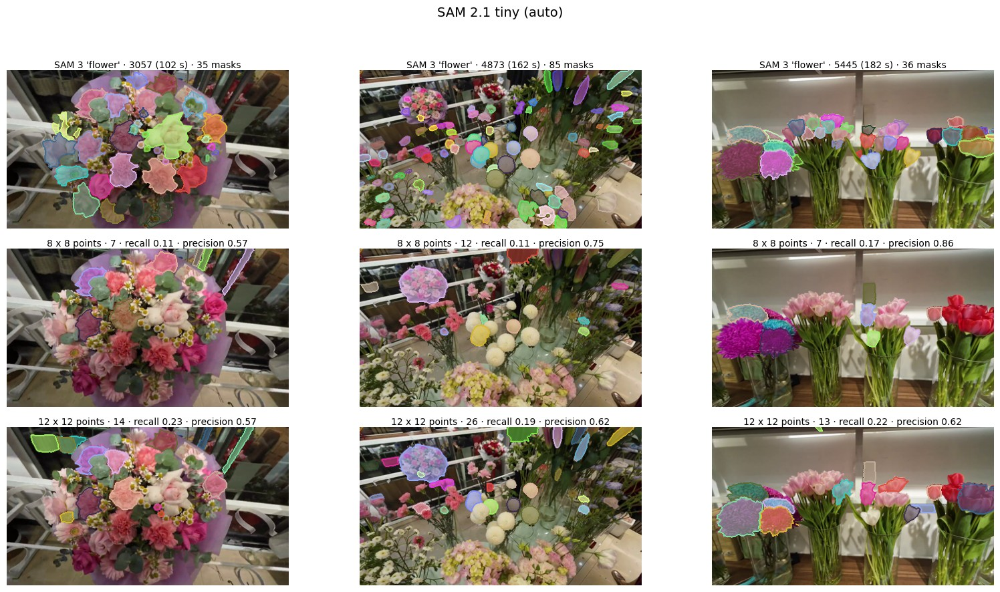

In [38]:
sweep_figure("SAM 2.1 tiny (auto)")

## 13 · Scoreboard

Averages over the 18 frames. F1 is computed from the average recall and
precision. **Higher is "closer to SAM 3", not "more correct".** A method can
also score well on recall by returning a huge number of candidates: read
recall together with precision and the candidate count.

In [39]:
board = (scores.groupby(["method", "setting"], sort=False)
         .agg(raw=("raw", "mean"), candidates=("kept", "mean"), recall=("recall", "mean"),
              precision=("precision", "mean"), pixel_f1=("pixel_f1", "mean"),
              seconds=("seconds", "mean")))
board["F1"] = 2 * board.recall * board.precision / (board.recall + board.precision).replace(0, np.nan)
board["F1"] = board["F1"].fillna(0.0)
board["fps"] = 1.0 / board.seconds
sam3_count = np.mean([len(keep(i, "flower")) for i in picks])
print(f"SAM 3 reference: {sam3_count:.1f} 'flower' masks per frame (score >= {SAM3_THR})")
ranked = board.sort_values("F1", ascending=False)
ranked.round({"raw": 0, "candidates": 1, "recall": 2, "precision": 2, "pixel_f1": 2,
              "seconds": 2, "F1": 2, "fps": 1})

SAM 3 reference: 47.8 'flower' masks per frame (score >= 0.5)


raw  candidates  recall  precision  pixel_f1  seconds    F1    fps
method                  setting                                                                                                    
FastSAM-s               imgsz 1024, conf 0.4                    81.0        47.3    0.42       0.43      0.61     0.96  0.42    1.0
                        imgsz 640, conf 0.4                     76.0        45.3    0.39       0.42      0.61     0.85  0.40    1.2
                        imgsz 1024, conf 0.6, iou 0.7           40.0        24.7    0.29       0.57      0.56     0.70  0.38    1.4
                        imgsz 1024, conf 0.2                   179.0       100.6    0.56       0.28      0.59     1.52  0.37    0.7
quick shift             kernel 5 / max dist 10                 176.0        86.2    0.33       0.19      0.47     2.07  0.24    0.5
SAM 2.1 tiny (auto)     12 x 12 points                          24.0        13.2    0.15       0.53      0.39    21.59  0.24    0.0
quick shift             kernel 3 / max dist 12                 273.0       127.6    0.35       0.14      0.45     0.92  0.20    1.1
watershed (colour mask) min distance 10px                       74.0        60.9    0.21       0.18      0.54     0.05  0.19   22.1
MobileSAM (point grid)  8 x 8 points                            47.0        16.8    0.13       0.35      0.41     6.83  0.19    0.1
watershed (colour mask) min distance 6px                       118.0        93.6    0.26       0.14      0.55     0.06  0.18   15.5
Felzenszwalb            scale 200                              314.0        73.0    0.22       0.15      0.38     0.32  0.18    3.1
SAM 2.1 tiny (auto)     8 x 8 points                            14.0         7.3    0.09       0.56      0.26     9.22  0.16    0.1
SLIC superpixels        400 superpixels, merged (colour 20)    146.0        69.8    0.18       0.13      0.42     0.93  0.15    1.1
HSV colour threshold    saturation >= 140                       38.0        19.5    0.11       0.23      0.26     0.00  0.15  264.2
SLIC superpixels        200 superpixels                        128.0        61.1    0.16       0.13      0.42     0.19  0.14    5.3
Felzenszwalb            scale 400                              169.0        39.3    0.12       0.17      0.30     0.20  0.14    4.9
watershed (colour mask) min distance 3px                       173.0       114.5    0.24       0.10      0.54     0.10  0.14    9.9
Felzenszwalb            scale 100                              565.0       137.1    0.26       0.09      0.41     0.57  0.14    1.8
HSV colour threshold    saturation >= 100                       42.0        23.7    0.10       0.20      0.24     0.00  0.13  274.6
MobileSAM (point grid)  6 x 6 points                            29.0        10.6    0.08       0.35      0.35     4.71  0.13    0.2
GrabCut on colour blobs 1 iteration(s)                          42.0        20.7    0.10       0.21      0.28     0.21  0.13    4.9
                        3 iteration(s)                          42.0        20.4    0.09       0.19      0.28     0.57  0.12    1.7
Hough circles           accumulator 25                         170.0       123.6    0.19       0.08      0.52     0.04  0.12   27.8
HSV colour threshold    saturation >= 100, plus white           51.0        22.1    0.08       0.19      0.21     0.00  0.11  219.6
SLIC superpixels        100 superpixels                         56.0        26.8    0.09       0.15      0.37     0.14  0.11    7.0
                        400 superpixels                        298.0       151.6    0.20       0.07      0.43     0.33  0.10    3.0
quick shift             kernel 3 / max dist 6                  513.0       225.9    0.28       0.06      0.45     1.79  0.10    0.6
k-means (Lab)           k = 8                                  414.0        70.3    0.11       0.09      0.28     0.06  0.10   16.1
Canny edge regions      thresholds 40/120                      223.0        81.3    0.11       0.08      

In [40]:
best = board.loc[board.groupby(level="method")["F1"].idxmax()].sort_values("F1", ascending=False)
best.round({"raw": 0, "candidates": 1, "recall": 2, "precision": 2, "pixel_f1": 2,
            "seconds": 2, "F1": 2, "fps": 1})

,,raw,candidates,recall,precision,pixel_f1,seconds,F1,fps
method,setting,,,,,,,,
FastSAM-s,"imgsz 1024, conf 0.4",81.0,47.3,0.42,0.43,0.61,0.96,0.42,1.0
quick shift,kernel 5 / max dist 10,176.0,86.2,0.33,0.19,0.47,2.07,0.24,0.5
SAM 2.1 tiny (auto),12 x 12 points,24.0,13.2,0.15,0.53,0.39,21.59,0.24,0.0
watershed (colour mask),min distance 10px,74.0,60.9,0.21,0.18,0.54,0.05,0.19,22.1
MobileSAM (point grid),8 x 8 points,47.0,16.8,0.13,0.35,0.41,6.83,0.19,0.1
Felzenszwalb,scale 200,314.0,73.0,0.22,0.15,0.38,0.32,0.18,3.1
SLIC superpixels,"400 superpixels, merged (colour 20)",146.0,69.8,0.18,0.13,0.42,0.93,0.15,1.1
HSV colour threshold,saturation >= 140,38.0,19.5,0.11,0.23,0.26,0.00,0.15,264.2
GrabCut on colour blobs,1 iteration(s),42.0,20.7,0.10,0.21,0.28,0.21,0.13,4.9


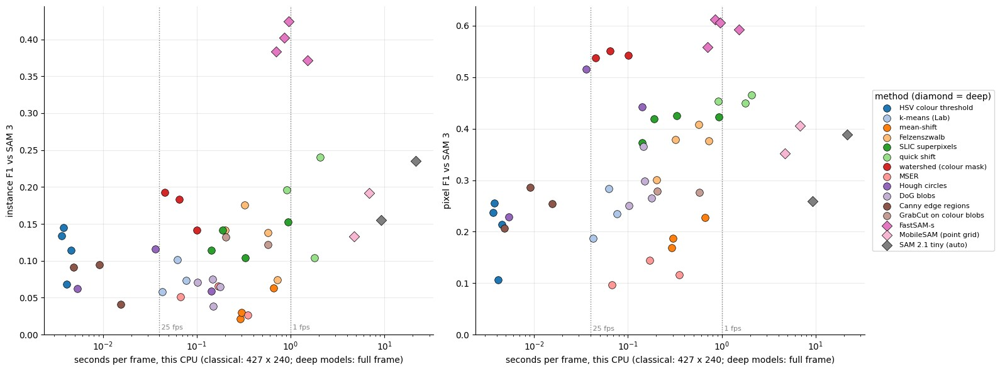

In [41]:
methods = list(SWEEPS)
palette = plt.cm.tab20(np.linspace(0, 1, 20))
colour = {m: palette[i % 20] for i, m in enumerate(methods)}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, column, title in ((axes[0], "F1", "instance F1 vs SAM 3"), (axes[1], "pixel_f1", "pixel F1 vs SAM 3")):
    for m in methods:
        part = board.loc[m]
        ax.scatter(part.seconds, part[column], s=70, color=colour[m], edgecolor="k",
                   linewidth=0.5, marker="D" if m in DEEP else "o", label=m, zorder=3)
    ax.axvline(1 / 25, color="gray", ls=":", lw=1)
    ax.text(1 / 25, 0.005, " 25 fps", color="gray", fontsize=8, va="bottom")
    ax.axvline(1.0, color="gray", ls=":", lw=1)
    ax.text(1.0, 0.005, " 1 fps", color="gray", fontsize=8, va="bottom")
    ax.set_xscale("log")
    ax.set_xlabel("seconds per frame, this CPU (classical: 427 x 240; deep models: full frame)")
    ax.set_ylabel(title)
    ax.set_ylim(0, None)
    ax.grid(alpha=0.25)
axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5), title="method (diamond = deep)")
plt.tight_layout()
plt.show()

## 14 · The best of each kind, next to SAM 3

For each method the **best setting by F1**. Rows: SAM 3, the three best small
deep models and the three best classical methods. Same three frames as before.

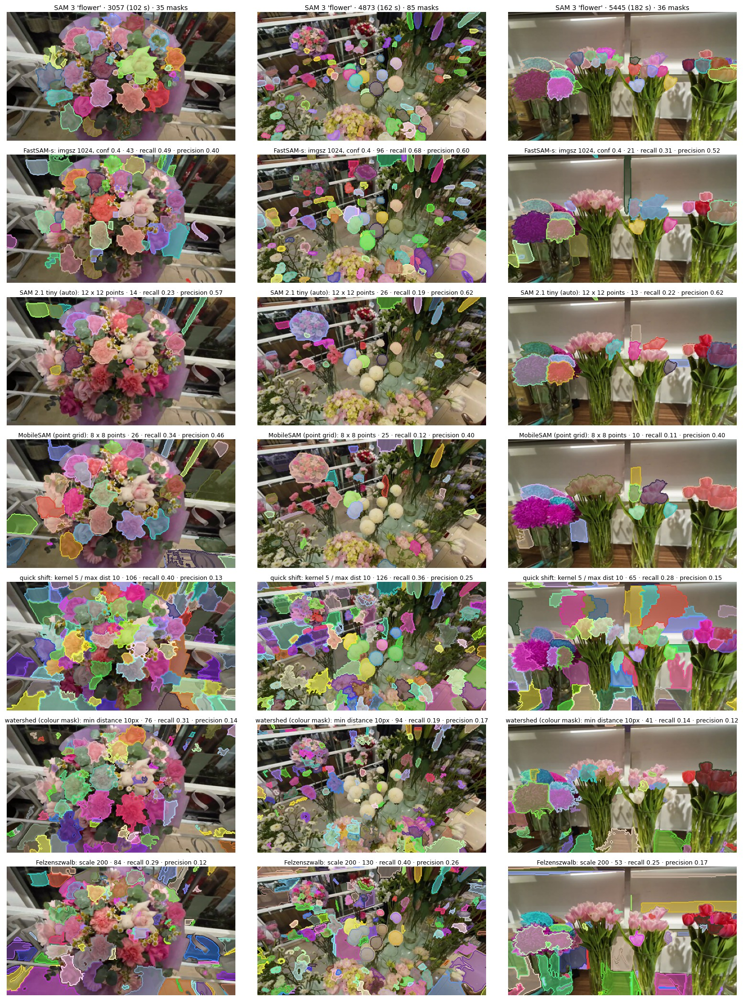

In [42]:
deep_best = [(m, s) for (m, s) in best.index if m in DEEP][:3]
classic_best = [(m, s) for (m, s) in best.index if m not in DEEP][:3]
rows_shown = deep_best + classic_best

fig, axes = plt.subplots(len(rows_shown) + 1, len(SHOW), figsize=(16, 3.0 * (len(rows_shown) + 1)))
for c, index in enumerate(SHOW):
    ref = keep(index, "flower")
    axes[0, c].imshow(sg.overlay_instances(small_frames[index], ref))
    axes[0, c].set_title(f"SAM 3 'flower' · {label(index)} · {len(ref)} masks", fontsize=10, pad=3)
    for r, (m, s) in enumerate(rows_shown, 1):
        found = candidates(m, s, index)
        a = cl.agreement(ref, found)
        axes[r, c].imshow(sg.overlay_instances(small_frames[index], found))
        axes[r, c].set_title(f"{m}: {s} · {len(found)} · recall {a['recall']:.2f} · "
                             f"precision {a['precision']:.2f}", fontsize=9, pad=3)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 15 · Every frame: the best small model and the best classical method

The same two-per-row layout as section 4, for the winner of each kind, so the
failures show up too (frames without flowers, hands, wrapping paper).

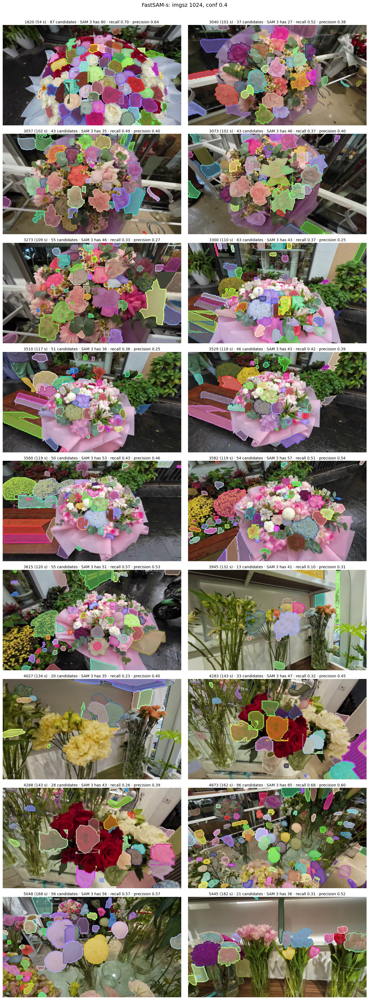

In [43]:
def show_method(family, setting):
    rows = -(-len(picks) // 2)
    fig, axes = plt.subplots(rows, 2, figsize=(14, 4.1 * rows))
    for ax, index in zip(axes.ravel(), picks):
        found = candidates(family, setting, index)
        a = cl.agreement(keep(index, "flower"), found)
        ax.imshow(sg.overlay_instances(small_frames[index], found))
        ax.set_title(f"{label(index)} · {len(found)} candidates · SAM 3 has "
                     f"{len(keep(index, 'flower'))} · recall {a['recall']:.2f} · "
                     f"precision {a['precision']:.2f}", fontsize=10, pad=4)
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.6 / (4.1 * rows)))
    fig.suptitle(f"{family}: {setting}", fontsize=14, y=1 - 0.1 / (4.1 * rows))
    plt.show()


show_method(*deep_best[0])

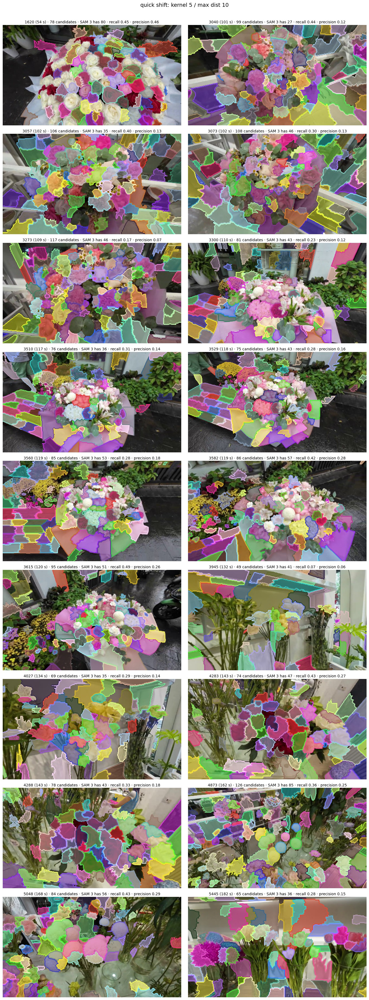

In [44]:
show_method(*classic_best[0])

## 16 · Take-aways from the small and classical methods

Every number is "agreement with SAM 3's `flower` masks" over these 18 frames,
not accuracy: SAM 3 has its own errors, and none of these methods says
anything about the species. Judgements come from the tables and pictures
above. Classical methods ran on the 427 x 240 image; the deep models got the
full 1280 x 720 frame, so their timings are for that size.

**FastSAM-s is the only method that gets close, and it is far from SAM 3.**

* Best setting (`imgsz 1024`, `conf 0.4`): recall 0.42, precision 0.43,
  pixel F1 0.61 at **0.96 s per frame (about 1 fps)**, roughly 50 times faster
  than SAM 3. It is not real time.
* `conf` is the knob: 0.2 gives recall 0.56 but precision 0.28 (about 100
  candidates per frame), while `conf 0.6` with `iou 0.7` gives recall 0.29 and
  precision 0.57 (about 25). `imgsz 640` is almost as good as 1024 (F1 0.40
  vs 0.42) and not much faster (0.85 s).
* Where it fails (section 15): the shelf frames 3945 and 4027 (recall 0.10 and
  0.23), the red-rose close-ups 4283 and 4288 (a few large merged masks, recall
  0.32 and 0.26), and boxes on wrapping paper, the wooden bench and potted
  plants in the street frames. It does best on many small heads (frames 4873
  and 1620: recall 0.68 / 0.70, precision 0.60 / 0.64).
* Section 17 (raw masks next to the filtered ones) shows that these misses are
  FastSAM's, not the filter's. In frames 3582, 3615 and 4027 it returns one huge
  mask over a whole bouquet or group of flowers instead of separate heads, and
  in the rose close-ups (4283, 4288) few individual roses are segmented. The
  filter only drops those huge masks (and vases, shelves and stems), as intended.

**The other small deep models are slow and find only a few large objects.**
SAM 2.1 tiny (12 x 12 points): 21.6 s per frame, recall 0.15, precision 0.53.
MobileSAM (8 x 8 points): 6.8 s per frame, recall 0.13, precision 0.35. They
are not a cheaper SAM 3.

**Classical methods do not separate flower heads.**

* The best instance F1 is 0.24 (quick shift), at 2 s per frame: slower and
  worse than FastSAM.
* **Watershed on the colour mask** is the interesting one: instance F1 only
  0.19, but pixel F1 0.54 at about **20 fps** (0.05 s). It finds *where the
  flower colour is* almost as well as FastSAM (0.61) but merges or splits
  heads wrongly. A plain HSV threshold does the same job coarsely at hundreds
  of frames per second (F1 0.15).
* k-means, mean-shift, MSER, Canny regions and DoG blobs are not useful here
  (F1 <= 0.11). Hough circles only reach recall 0.38 with about 600 candidates
  per frame (precision 0.03).
* The shared filter also throws away white flowers by design (a known cost,
  the same for every method).

**What this means for the plan.**

* No method that needs no training gives both speed and good heads: the
  best is FastSAM at 1 fps with about 0.4 recall and 0.4 precision against
  SAM 3, and it also boxes background. Something trained on flower heads has
  to do better on both counts, but that is *not measured here*.
* For the safety rule the important number is recall: even with the noisy
  `conf 0.2` setting, 44% of SAM 3's flower masks have no matching FastSAM
  candidate (IoU >= 0.5), and a missed head is silent. Nothing here should be used to say a bouquet has no toxic flower.
* If we train our own detector, FastSAM and the colour watershed are useful as
  cheap suggestions to review, not as the answer.

## 17 · FastSAM-s next to SAM 3, on every frame

Three columns per frame:

1. **SAM 3** `flower` (score >= 0.5), the reference.
2. **FastSAM-s, every mask it returned** (raw, before any filter): `imgsz 1024`,
   `conf 0.4`, the best setting in section 13.
3. **FastSAM-s after the `flowerlike` filter** (the candidates that were
   scored in sections 13-15).

Comparing 2 and 3 shows whether a flower that is not outlined in column 3 was
never found by FastSAM or was thrown away by my filter. The titles give the
mask counts, and recall / precision against SAM 3 for column 3. Two figures,
nine frames each. The raw masks are computed once (about 1 s per frame) and
cached in `data/raw/cache/small_seg/`.

In [45]:
FASTSAM_SETTING = "imgsz 1024, conf 0.4"            # a cached label from section 12
FASTSAM_KWARGS = {"imgsz": 1024, "conf": 0.4}       # the same setting as arguments


def raw_fastsam(index):
    stem = SMALL_DIR / f"{path.stem}_fastsam-raw__{slug(FASTSAM_SETTING)}_f{index}.npz"
    if stem.exists():
        return sg.load_results(stem)["raw"]
    masks = model("fastsam").segment(frames[index].image, **FASTSAM_KWARGS)
    sg.save_results(stem, {"raw": masks})
    return masks


raw_masks = {index: raw_fastsam(index) for index in picks}
MODELS.clear()
gc.collect()
print("raw FastSAM masks per frame:", {index: len(m) for index, m in raw_masks.items()})

raw FastSAM masks per frame: {1620: 113, 3040: 77, 3057: 73, 3073: 75, 3273: 100, 3300: 149, 3510: 105, 3529: 114, 3560: 78, 3582: 94, 3615: 103, 3945: 29, 4027: 28, 4283: 44, 4288: 43, 4873: 116, 5048: 71, 5445: 40}


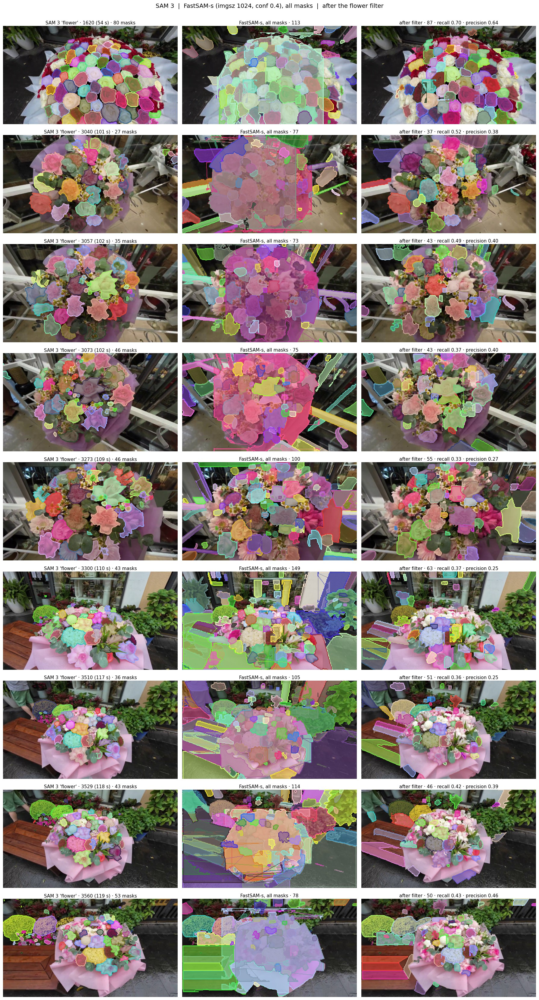

In [46]:
def three_columns(indices, family="FastSAM-s", setting=FASTSAM_SETTING):
    fig, axes = plt.subplots(len(indices), 3, figsize=(18, 3.7 * len(indices)))
    for row, index in zip(axes, indices):
        ref = keep(index, "flower")
        raw = raw_masks[index]
        found = candidates(family, setting, index)
        a = cl.agreement(ref, found)
        row[0].imshow(sg.overlay_instances(small_frames[index], ref))
        row[0].set_title(f"SAM 3 'flower' · {label(index)} · {len(ref)} masks", fontsize=11, pad=4)
        row[1].imshow(sg.overlay_instances(small_frames[index], raw))
        row[1].set_title(f"{family}, all masks · {len(raw)}", fontsize=11, pad=4)
        row[2].imshow(sg.overlay_instances(small_frames[index], found))
        row[2].set_title(f"after filter · {len(found)} · recall {a['recall']:.2f} · "
                         f"precision {a['precision']:.2f}", fontsize=11, pad=4)
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.5 / (3.7 * len(indices))))
    fig.suptitle(f"SAM 3  |  {family} ({setting}), all masks  |  after the flower filter",
                 fontsize=14, y=1 - 0.08 / (3.7 * len(indices)))
    plt.show()


three_columns(picks[:9])

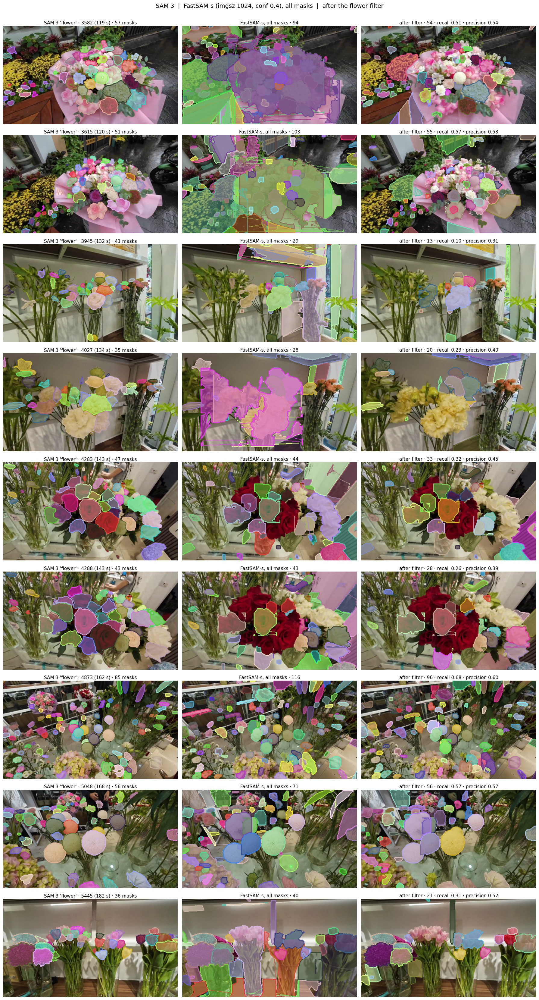

In [47]:
three_columns(picks[9:])